# KV-cache compression on Qwen3-8B: diagnostics E0–E6, memory and latency

One notebook, one model per run. It runs the diagnostics E0–E6 and the memory and latency benchmark (§17).
MMLU and LongBench (§18) sit behind flags that default to off. The plan behind it is
*Consolidated notebook plan E0–E6 + §13 on Qwen3-8B.md*; the cluster workflow is in *cluster_run_plan.md*.

**Presets.** `PRESET = "smoke"` runs every section on tiny settings (1 document, 6 facts, 800 tokens) to check
the pipeline in minutes: run it on `Qwen/Qwen2.5-0.5B`, then on `Qwen/Qwen3-8B`. `PRESET = "full"` is the real
run (30 documents × 20 facts × about 3k tokens of natural prose).

**Lanes.** `LANE` picks which sections a run executes, so the experiments can be split across GPUs.

| `LANE` | Runs |
|---|---|
| `all`, `smoke`, `final` | everything, then the summary (§19) |
| `exp-a` | E0 → E2 → E3 → E6 (E2, E3 and E6 use E0's probe budgets) |
| `exp-b` | E5 → E1 → E4 |
| `bench` | memory and latency only, in a fresh process |
| `optional` | MMLU and LongBench, if `RUN_MMLU` / `RUN_LONGBENCH` |

**Resume.** Each arm is saved to `<results>/<model>/<experiment>/arms/` as soon as it finishes, and the memory
benchmark is saved per repeat. Running the notebook again from the top loads finished arms instead of running
them, so a disconnect or a preemption costs at most one arm. Delete an arm's file to rerun it, or an
experiment's folder to rerun the experiment. An arm's file name includes a hash of everything that changes its
result (config, scoring signal, haystack, model, document settings), so changing a knob never reuses a stale arm.

**Where results go.** On Colab: Google Drive, `MyDrive/kv_cache_results/<model>/`. Elsewhere: `$KV_RESULTS_DIR`,
or `./kv_cache_results`. Smoke runs write to a sibling folder ending in `_smoke`.

**How to run.** Colab: set the parameters in the next cell, then run all. Cluster (headless, via papermill):
`sbatch -J kvc-smoke cluster/run.sbatch smoke smoke Qwen/Qwen2.5-0.5B` for a smoke test, `bash cluster/submit.sh`
for the full run.

**Expected runtime (full preset).** About 5–10 h for E0–E6 on one A100, and up to twice that on an L40S or A6000;
two experiment lanes on two GPUs halve it. Every experiment prints its measured seconds per arm, which replace
these estimates.

**Implementation notes** (unchanged from the first run).
* A custom attention backend (`kv_compress`, SDPA-based) records $a_{i,l}$ during prefill: the attention mass
  that the last `OBS_WINDOW` prefix queries put on each token, averaged over heads (SnapKV-style). It builds its
  own causal mask, so it stays correct after eviction, when cache length ≠ position index.
* Keys are cached after RoPE (and, on Qwen3, after QK-norm), and new tokens are fed with their *original*
  position ids, so eviction never shifts positions.
* The first `SINK_TOKENS` and last `OBS_WINDOW` prefix tokens always stay at 16 bits; only the tokens between
  them are scored, evicted or quantized. Their bytes count against the budget.
* Quantization is asymmetric min-max with fp16 scale and zero: per channel over 32-token groups for keys (KIVI),
  per token over 32-channel groups for values. 4-bit and 2-bit codes are packed two and four per byte.
  Quantized tokens are dequantized on the fly at every decode step, in plain PyTorch.
* All retrieval metrics are on a prefix compressed **before any question is seen**, then reused for every question.

In [1]:
# Parameters. cluster/run.sbatch overrides these through papermill; on Colab, edit them here.
PRESET = "full"             # "full": the real run. "smoke": every section on tiny settings
MODEL_ID = "Qwen/Qwen3-8B"  # smoke-test model: "Qwen/Qwen2.5-0.5B"
LANE = "all"                # all | smoke | final | exp-a | exp-b | bench | optional (see §0)
RESULTS_ROOT = None         # None: Drive on Colab, else $KV_RESULTS_DIR or ./kv_cache_results
RUN_MMLU = False            # optional benchmarks (§18)
RUN_LONGBENCH = False

In [2]:
# Parameters
PRESET = "full"
MODEL_ID = "Qwen/Qwen3-8B"
LANE = "final"


## 1. Install and imports
On Colab this installs the pinned packages (`lm_eval` only when MMLU or LongBench is on). Elsewhere, the
environment is expected to have them already (`cluster/setup.sh` builds it).

In [3]:
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    _pkgs = ["torch>=2.6", "transformers==4.57.1", "accelerate>=0.26.0", "sentencepiece", "pandas", "matplotlib",
             "datasets"]
    if RUN_MMLU or RUN_LONGBENCH:
        _pkgs.append("lm_eval[hf,longbench]==0.4.11")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_pkgs])

import gc
import hashlib
import json
import math
import random
import re
import shutil
import socket
import time
from collections import defaultdict
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
from typing import Optional, Union

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed


def pkg_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return None


def nvidia_smi(query):
    try:
        out = subprocess.run(["nvidia-smi", f"--query-gpu={query}", "--format=csv,noheader"],
                             capture_output=True, text=True, timeout=30).stdout.strip()
        return out.splitlines()[0] if out else None
    except Exception:
        return None


VERSIONS = {name: pkg_version(name) for name in
            ["torch", "transformers", "accelerate", "datasets", "lm_eval", "papermill", "numpy", "pandas"]}
VERSIONS["python"] = sys.version.split()[0]
VERSIONS["cuda_runtime"] = torch.version.cuda
if torch.cuda.is_available():
    _props = torch.cuda.get_device_properties(0)
    GPU = {"name": torch.cuda.get_device_name(0), "memory_GiB": round(_props.total_memory / 2**30, 1),
           "driver": nvidia_smi("driver_version"), "uuid": nvidia_smi("uuid")}
else:
    GPU = {"name": "cpu"}
print(VERSIONS)
print(GPU)

/home/alsalali/orcd/pool/venvs/kvcache/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'torch': '2.11.0+cu128', 'transformers': '4.57.1', 'accelerate': '1.16.0', 'datasets': '3.6.0', 'lm_eval': '0.4.11', 'papermill': '2.7.0', 'numpy': '2.5.5', 'pandas': '2.3.3', 'python': '3.12.13', 'cuda_runtime': '12.8'}
{'name': 'NVIDIA L40S', 'memory_GiB': 44.4, 'driver': '590.48.01', 'uuid': 'GPU-d4982361-642a-b5a8-edd7-46f2b9137a85'}


## 2. Configuration
Every knob is here. `pick(full, smoke)` gives the value for the current preset. Budgets are fractions of the
fp16 KV-cache bytes; `"int4"` / `"int8"` resolve, for each input, to exactly the bytes uniform 4/8-bit
quantization uses, which gives byte-matched comparisons.

In [4]:
assert PRESET in ("full", "smoke"), f"unknown PRESET {PRESET!r}"
SMOKE = PRESET == "smoke"


def pick(full, smoke):
    return smoke if SMOKE else full


# Which sections run, by lane (cluster_run_plan.md). Experiments run in priority order: E0, E5, E2, E1, E3, E4, E6.
_EVERYTHING = ["E0", "E5", "E2", "E1", "E3", "E4", "E6", "BENCH", "OPTIONAL", "SUMMARY"]
LANES = {"all": _EVERYTHING, "smoke": _EVERYTHING, "final": _EVERYTHING,
         "exp-a": ["E0", "E2", "E3", "E6"], "exp-b": ["E5", "E1", "E4"],
         "bench": ["BENCH"], "optional": ["OPTIONAL"]}
assert LANE in LANES, f"unknown LANE {LANE!r}; choose from {list(LANES)}"
_parts = set(LANES[LANE])
RUN_E0, RUN_E5, RUN_E2, RUN_E1, RUN_E3, RUN_E4, RUN_E6 = (f"E{i}" in _parts for i in (0, 5, 2, 1, 3, 4, 6))
RUN_ANY_E = RUN_E0 or RUN_E1 or RUN_E2 or RUN_E3 or RUN_E4 or RUN_E5 or RUN_E6
RUN_BENCH = "BENCH" in _parts
RUN_OPTIONAL = "OPTIONAL" in _parts and (RUN_MMLU or RUN_LONGBENCH)
RUN_SUMMARY = "SUMMARY" in _parts

# Compression hyperparameters (unchanged from the first run)
SINK_TOKENS = 4
OBS_WINDOW = 32            # last W prefix tokens: always kept at 16 bits; their queries give a_{i,l}
POOL_KERNEL = 7
LAMBDA = 1.0               # main ILF weight
TIER_SPLIT = (1 / 3, 1 / 3, 1 / 3)  # default budget share of the 16 / 8 / 4-bit tiers in mixed precision
QUERY_AWARE = False        # False: LongBench prefixes are compressed before the question is seen
SEED = 42

# Retrieval experiments (E0-E6)
HAYSTACK = "natural"       # primary haystack for E0-E3 and E5; E4 and E6 run both "natural" and "repeat"
EXP_DOCS = pick(30, 1)     # documents per arm
RETRIEVAL_FACTS = pick(20, 6)      # facts (questions) per document
RETRIEVAL_TOKENS = pick(3000, 800)  # document length, as in the first run
KEEP_GRID = pick([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], [0.5])  # E0 and E4 budgets (E4 adds 0.1 and 0.2)
E5_BUDGETS = pick([0.1, 0.2, "int4"], [0.2])
PROBE_BUDGETS_FALLBACK = pick([0.6, 0.8], [0.5])  # E2, E3, E6 budgets if E0 has not picked them
AUTO_PROBE_BUDGETS = True  # E0 picks budgets where attention selection scores 20-80% of the full cache
EXP_GENERATE = False       # also greedy-decode in E1-E6 (slower); E0 always decodes
GATE_MIN_TF_EXACT = 0.7    # headroom gate: full-cache teacher-forced exact match on the primary haystack

# Memory and latency (§17)
BENCH_BATCH = pick(4, 1)
BENCH_SEQ_LEN = pick(4096, 512)
BENCH_DECODE_TOKENS = pick(64, 8)
BENCH_REPEATS = pick(3, 1)
BENCH_WARMUP_STEPS = 3     # untimed decode steps per method before the timed ones

# Optional benchmarks (§18)
MAX_INPUT_TOKENS = pick(4096, 2048)
MMLU_TASKS = pick(["mmlu"], ["mmlu_abstract_algebra"])
MMLU_LIMIT = pick(10, 4)   # per subject: 57 x 10 = 570 questions
MMLU_FEWSHOT = pick(5, 0)
LONGBENCH_TASKS = pick(["longbench_hotpotqa", "longbench_2wikimqa", "longbench_multifieldqa_en",
                        "longbench_qasper", "longbench_passage_retrieval_en"], ["longbench_hotpotqa"])
LONGBENCH_LIMIT = pick(200, 2)

CONFIG = {k: globals()[k] for k in [
    "PRESET", "MODEL_ID", "LANE", "RUN_E0", "RUN_E5", "RUN_E2", "RUN_E1", "RUN_E3", "RUN_E4", "RUN_E6", "RUN_BENCH",
    "RUN_MMLU", "RUN_LONGBENCH", "SINK_TOKENS", "OBS_WINDOW", "POOL_KERNEL", "LAMBDA", "TIER_SPLIT", "QUERY_AWARE",
    "SEED", "HAYSTACK", "EXP_DOCS", "RETRIEVAL_FACTS", "RETRIEVAL_TOKENS", "KEEP_GRID", "E5_BUDGETS",
    "PROBE_BUDGETS_FALLBACK", "AUTO_PROBE_BUDGETS", "EXP_GENERATE", "GATE_MIN_TF_EXACT", "BENCH_BATCH",
    "BENCH_SEQ_LEN", "BENCH_DECODE_TOKENS", "BENCH_REPEATS", "BENCH_WARMUP_STEPS", "MAX_INPUT_TOKENS",
    "MMLU_TASKS", "MMLU_LIMIT", "MMLU_FEWSHOT", "LONGBENCH_TASKS", "LONGBENCH_LIMIT"]}
set_seed(SEED)
print(f"PRESET={PRESET}  MODEL_ID={MODEL_ID}  LANE={LANE}")
print("runs:", [k for k in ("RUN_E0", "RUN_E5", "RUN_E2", "RUN_E1", "RUN_E3", "RUN_E4", "RUN_E6", "RUN_BENCH",
                            "RUN_OPTIONAL", "RUN_SUMMARY") if globals()[k]])

PRESET=full  MODEL_ID=Qwen/Qwen3-8B  LANE=final
runs: ['RUN_E0', 'RUN_E5', 'RUN_E2', 'RUN_E1', 'RUN_E3', 'RUN_E4', 'RUN_E6', 'RUN_BENCH', 'RUN_SUMMARY']


## 3. Results I/O and resume
`OUT` is the per-model results folder. Every file is written to a temporary name and then renamed into place,
so a run killed mid-write never leaves a partial file that looks finished. Each lane keeps its own manifest
(`manifest/<lane>.json`, one entry per attempt: job, node, GPU, versions, knobs, times per experiment);
§19 merges them into `run_manifest.json`.

In [5]:
if RESULTS_ROOT is not None:
    _root = Path(RESULTS_ROOT)
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    _root = Path("/content/drive/MyDrive/kv_cache_results")
else:
    _root = Path(os.environ.get("KV_RESULTS_DIR", "kv_cache_results"))
if SMOKE and RESULTS_ROOT is None:
    _root = _root.with_name(_root.name + "_smoke")
MODEL_SLUG = MODEL_ID.replace("/", "__")
OUT = (_root / MODEL_SLUG).resolve()
OUT.mkdir(parents=True, exist_ok=True)

RUN_INFO = {"lane": LANE, "preset": PRESET, "model": MODEL_ID, "host": socket.gethostname(),
            "job_id": os.environ.get("SLURM_JOB_ID"), "attempt": int(os.environ.get("SLURM_RESTART_COUNT", 0)),
            "pid": os.getpid()}


def now():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")


def atomic_write(path, write):
    """Call `write(tmp_path)`, then rename tmp_path to `path` (atomic on one filesystem)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(f".{path.name}.tmp-{os.getpid()}")
    write(tmp)
    os.replace(tmp, path)


def save_table(df, name):
    path = OUT / f"{name}.csv"
    atomic_write(path, lambda p: df.to_csv(p, index=False))
    print(f"Saved {path}")


def read_csv(path):
    # "budget" mixes numbers and strings ("0.5", "int8"): always read it as text, as `describe` writes it.
    return pd.read_csv(path, dtype={"budget": str})


def read_table(name):
    path = OUT / f"{name}.csv"
    return read_csv(path) if path.exists() else None


def save_json(path, obj):
    atomic_write(path, lambda p: Path(p).write_text(json.dumps(obj, indent=2, default=str)))


def save_npy(path, array):
    def write(p):
        with open(p, "wb") as f:
            np.save(f, array)
    atomic_write(path, write)


def slug(text):
    return re.sub(r"[^A-Za-z0-9.=_-]+", "_", str(text)).strip("_")


def git_info():
    def git(*args):
        return subprocess.run(["git", *args], capture_output=True, text=True, timeout=10).stdout.strip()
    try:
        return {"commit": git("rev-parse", "HEAD") or None, "branch": git("rev-parse", "--abbrev-ref", "HEAD") or None,
                "dirty": bool(git("status", "--porcelain", "--untracked-files=no"))}
    except Exception as e:
        return {"error": repr(e)}


class Manifest:
    """One JSON file per lane, because lanes run at the same time. Each attempt (a preemption restart is a new
    attempt) appends one entry; experiments record start/end times and how many arms were run or loaded."""

    def __init__(self, path):
        self.path = path
        self.data = json.loads(path.read_text()) if path.exists() else {"lane": LANE, "attempts": []}
        self.attempt = {**RUN_INFO, "start": now(), "versions": VERSIONS, "gpu": GPU, "git": git_info(),
                        "config": CONFIG, "experiments": {}}
        self.data["attempts"].append(self.attempt)
        self.save()

    def save(self):
        save_json(self.path, self.data)

    def set(self, key, value):
        self.attempt[key] = value
        self.save()

    def exp(self, name):
        return self.attempt["experiments"].setdefault(name, {"arms_run": 0, "arms_cached": 0, "seconds_run": 0.0})

    def begin(self, name):
        self.exp(name)["start"] = now()
        self.save()

    def end(self, name, **info):
        self.exp(name).update(end=now(), **info)
        self.save()

    def arm_done(self, name, cached, seconds):
        e = self.exp(name)
        if cached:
            e["arms_cached"] += 1
        else:
            e["arms_run"] += 1
            e["seconds_run"] += seconds
        self.save()


MANIFEST = Manifest(OUT / "manifest" / f"{LANE}.json")
print(f"Results: {OUT}")
print(f"Attempt {RUN_INFO['attempt']} of job {RUN_INFO['job_id']} on {RUN_INFO['host']}")

Results: /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B
Attempt 0 of job 29512388 on node3405


## 4. Attention backend: recording $a_{i,l}$
`kv_compression_attention` replaces eager attention. While `RECORDER` is active (only during the prefill of a
compressed method), each layer stores $a_{i,l} = \operatorname{mean}_{h,\,q \in \text{window}}
\operatorname{softmax}(q K^\top/\sqrt{d})_i$ (or the max, or a mean over the queries that can see each key).
Unchanged from the first run.

In [6]:
import math
import torch.nn.functional as F
from transformers import AttentionInterface


class AttentionScoreRecorder:
    """While active, stores a_{i,l} for every layer l: attention from the last `window`
    query positions to the first `n_keys` keys (default: all), reduced over query heads
    and window queries.

    reduce: "mean"          average over heads and window queries (SnapKV-style, the default)
            "mean_visible"  like "mean", but each key is averaged only over the window queries
                            that can see it (needed when the window covers the whole prefix)
            "max"           strongest single (head, query) pair (KVzip-style)"""

    def __init__(self):
        self.active, self.window, self.n_keys, self.reduce, self.scores = False, 32, None, "mean", {}

    def start(self, window, n_keys=None, reduce="mean"):
        self.active, self.window, self.n_keys, self.reduce, self.scores = True, window, n_keys, reduce, {}

    def stop(self):
        scores, self.active, self.scores = self.scores, False, {}
        return scores


RECORDER = AttentionScoreRecorder()
SCORE_QUERY_CHUNK = 128  # window queries scored at a time; bounds memory for long scoring windows


def _window_attention(query, key, scaling, window, n_keys=None, reduce="mean"):
    """[b, Hq, q, d] x [b, Hkv, k, d] -> [b, n_keys] attention mass from the last `window` queries.
    Grouped-query heads are handled without materialising repeated keys, and the window is
    processed in chunks of SCORE_QUERY_CHUNK queries."""
    b, hq, q_len, d = query.shape
    hk, k_len = key.shape[1], key.shape[2]
    n_rep, w = hq // hk, min(window, q_len)
    n_keys = k_len if n_keys is None else min(n_keys, k_len)
    key_t = key.float().transpose(-1, -2)
    key_pos = torch.arange(k_len, device=query.device)
    out = torch.zeros(b, n_keys, device=query.device)
    for start in range(q_len - w, q_len, SCORE_QUERY_CHUNK):
        stop = min(start + SCORE_QUERY_CHUNK, q_len)
        q = query[:, :, start:stop].float().reshape(b, hk, n_rep * (stop - start), d)  # rows ordered (rep, query pos)
        logits = torch.matmul(q, key_t) * scaling
        q_pos = (torch.arange(start, stop, device=query.device) + (k_len - q_len)).repeat(n_rep)
        logits.masked_fill_(key_pos[None, :] > q_pos[:, None], float("-inf"))
        probs = logits.softmax(-1)[..., :n_keys]
        if reduce == "max":
            out = torch.maximum(out, probs.amax(dim=(1, 2)))
        else:
            out += probs.sum(dim=(1, 2))
    if reduce == "max":
        return out
    if reduce == "mean_visible":  # number of window queries at or after each key position
        visible = (k_len - key_pos[:n_keys].clamp_min(k_len - w)).clamp_min(1)
        return out / (hk * n_rep * visible)
    return out / (hk * n_rep * w)


def kv_compression_attention(module, query, key, value, attention_mask, scaling=None, dropout=0.0, **kwargs):
    """SDPA attention that (1) optionally records window attention scores and
    (2) builds its own mask, so it works on caches whose length no longer equals the
    position index (after eviction). Assumes unpadded batches (no left padding)."""
    scaling = scaling if scaling is not None else 1.0 / math.sqrt(query.shape[-1])
    if RECORDER.active:
        RECORDER.scores[module.layer_idx] = _window_attention(query, key, scaling, RECORDER.window,
                                                              RECORDER.n_keys, RECORDER.reduce)
    n_rep = query.shape[1] // key.shape[1]
    if n_rep > 1:
        key = key.repeat_interleave(n_rep, dim=1)
        value = value.repeat_interleave(n_rep, dim=1)
    q_len, k_len = query.shape[2], key.shape[2]
    if q_len == 1:  # decoding: every retained cache entry is visible
        out = F.scaled_dot_product_attention(query, key, value, scale=scaling)
    elif q_len == k_len:  # prefill with an empty cache
        out = F.scaled_dot_product_attention(query, key, value, is_causal=True, scale=scaling)
    else:  # several new tokens on top of a (compressed) cache: causal among the new tokens
        q_pos = torch.arange(k_len - q_len, k_len, device=query.device)
        allowed = torch.arange(k_len, device=query.device)[None, :] <= q_pos[:, None]
        out = F.scaled_dot_product_attention(query, key, value, attn_mask=allowed, scale=scaling)
    return out.transpose(1, 2).contiguous(), None


AttentionInterface.register("kv_compress", kv_compression_attention)
print("Registered attention backend 'kv_compress'.")

Registered attention backend 'kv_compress'.


## 5. Scoring and bit allocation
For every layer $l$ and candidate token $i$:

$$d_i=\sum_{l=1}^{L}\mathbf 1[a_{i,l}>\tau_l],\qquad \mathrm{ILF}_i=\log\frac{L+1}{d_i+1},\qquad S_{i,l}=a_{i,l}\,(1+\lambda\,\mathrm{ILF}_i)$$

By default $\tau_l$ is layer $l$'s $(1-k)$ quantile of attention, where $k$ is the fraction of tokens the budget
lets us keep, so $d_i$ counts the layers in which plain attention selection would keep token $i$.
`selection_scores` also implements the alternatives the experiments compare: `ilf_gated`, `lf`, `mix`,
`segment`, `idf` and two random rankings. **select** keeps the top tokens per layer at 16 bits; **mixed** fills a
16-bit, then an 8-bit, then a 4-bit tier (`tier_split` shares the bytes); the rest are evicted.

In [7]:
from dataclasses import dataclass
from typing import Optional, Union


@dataclass(frozen=True)
class KVCompressionConfig:
    """One compression method.

    method:  "full"   - no compression (baseline)
             "select" - dynamic selection: keep the top tokens at 16 bits, evict the rest
             "quant"  - uniform quantization of every token to `quant_bits`
             "mixed"  - mixed precision: tokens ranked by score get 16 / 8 / 4 / 0 bits
    budget:  fraction of the fp16 KV-cache bytes to keep, or "int4"/"int8" to match the
             byte footprint of uniform 4/8-bit quantization on the same input.
    lam:     lambda in S_{i,l} = a_{i,l} (1 + lambda * ILF_i). lam = 0 is plain attention scoring.
    score_mode: how per-layer attention a_{i,l} becomes the selection score (see `selection_scores`):
             "ilf" (default), "ilf_gated", "lf", "mix", "segment", "idf", "random_shared", "random_layer".
    """

    name: str
    method: str = "full"
    budget: Union[float, str] = 1.0
    lam: float = 0.0
    quant_bits: int = 8
    tier_split: tuple = (1 / 3, 1 / 3, 1 / 3)  # share of the budget spent on 16 / 8 / 4-bit tiers
    sink_tokens: int = 4    # first tokens, always kept at 16 bits (attention sinks)
    window: int = 32        # last tokens, always kept at 16 bits; their queries score the rest
    pool_kernel: int = 7    # 1-D average pooling of scores along tokens (SnapKV-style); 1 disables
    tau_quantile: Optional[float] = None  # per-layer tau_l quantile; None -> 1 - keep fraction
    score_mode: str = "ilf"
    layer_mix: float = 0.0  # "mix": 0 = every layer ranks on its own, 1 = one shared ranking for all layers
    n_segments: int = 16    # "segment": number of contiguous prefix blocks that get equal keep quotas
    seed: int = 0           # "random_*" modes


def bytes_ratio(bits, head_dim, group=32):
    """Approximate bytes per stored token relative to fp16, including the fp16 scale + zero
    stored for every group of `group` elements (keys and values alike)."""
    if bits == 16:
        return 1.0
    if bits == 0:
        return 0.0
    return (bits / 8 + 4 / min(group, head_dim)) / 2


def resolve_budget(cfg, n_tokens, n_forced, head_dim):
    if isinstance(cfg.budget, str):  # "int4" / "int8": match uniform quantization
        bits = int(cfg.budget.removeprefix("int"))
        return (n_forced + (n_tokens - n_forced) * bytes_ratio(bits, head_dim)) / n_tokens
    return float(cfg.budget)


def tier_counts(cfg, n_tokens, n_forced, head_dim):
    """Number of candidate tokens (outside sinks/window) to store at 16, 8 and 4 bits."""
    n_cand = n_tokens - n_forced
    budget = resolve_budget(cfg, n_tokens, n_forced, head_dim)
    remaining = max(budget * n_tokens - n_forced, 0.0)  # in fp16-token units
    if cfg.method == "select":
        return min(n_cand, int(remaining)), 0, 0
    counts, left = [], n_cand
    for share, bits in zip(cfg.tier_split, (16, 8, 4)):
        n = min(left, int(remaining * share / bytes_ratio(bits, head_dim)))
        counts.append(n)
        left -= n
    return tuple(counts)


def ilf_diversified_scores(attn, lam, keep_fraction, tau_quantile=None):
    """attn: a_{i,l} as [L, batch, tokens].
    d_i     = sum_l 1[a_{i,l} > tau_l]
    ILF_i   = log((L + 1) / (d_i + 1))
    S_{i,l} = a_{i,l} (1 + lam * ILF_i)
    tau_l defaults to layer l's (1 - keep_fraction) quantile, i.e. "token i would be kept
    by plain attention selection in layer l"."""
    n_layers = attn.shape[0]
    q = tau_quantile if tau_quantile is not None else 1.0 - keep_fraction
    q = min(max(q, 0.0), 1.0)
    tau = torch.quantile(attn, q, dim=-1, keepdim=True)
    d = (attn > tau).sum(0)
    ilf = torch.log((n_layers + 1) / (d.float() + 1))
    return attn * (1 + lam * ilf), d, ilf


def _rank01(x):
    """Rank of every entry along the last dim, scaled to [0, 1] (1 = largest)."""
    return x.argsort(-1).argsort(-1).float() / max(x.shape[-1] - 1, 1)


def selection_scores(attn, cfg, keep_fraction, token_ids=None):
    """Selection score S_{i,l} [L, batch, tokens] from attention a_{i,l}, by `cfg.score_mode`.

    "ilf"            a (1 + lam * ILF_i): the proposal. More cross-layer diversity as lam grows.
    "ilf_gated"      as "ilf", but tokens that no layer would keep (d_i = 0) get no boost.
    "lf"             a (1 + lam * log(1 + d_i)): the opposite of ILF, boosts tokens many layers want.
    "mix"            (1 - layer_mix) * r_{i,l} + layer_mix * mean_l r_{i,l}, r = per-layer rank in [0, 1].
                     layer_mix = 0 is plain attention; layer_mix = 1 keeps the same tokens in every layer.
    "segment"        rank of a_{i,l} inside its block of the prefix (`n_segments` equal blocks),
                     so every block keeps the same share of its tokens (diversity over positions).
    "idf"            a (1 + lam * log(M / count_i)), count_i = occurrences of token i's id among the
                     M candidates (diversity over content: literal tf-idf). Needs `token_ids` [batch, tokens].
    "random_shared"  random ranking shared by all layers.   "random_layer": independent per layer."""
    mode, n_tok = cfg.score_mode, attn.shape[-1]
    if mode == "ilf":
        return ilf_diversified_scores(attn, cfg.lam, keep_fraction, cfg.tau_quantile)[0]
    if mode in ("ilf_gated", "lf"):
        _, d, ilf = ilf_diversified_scores(attn, cfg.lam, keep_fraction, cfg.tau_quantile)
        boost = ilf * (d > 0) if mode == "ilf_gated" else torch.log1p(d.float())
        return attn * (1 + cfg.lam * boost)
    if mode == "mix":
        r = _rank01(attn)
        return (1 - cfg.layer_mix) * r + cfg.layer_mix * r.mean(0, keepdim=True)
    if mode == "segment":
        s = torch.empty_like(attn, dtype=torch.float32)
        edges = torch.linspace(0, n_tok, min(cfg.n_segments, n_tok) + 1).round().long().tolist()
        for lo, hi in zip(edges[:-1], edges[1:]):
            s[..., lo:hi] = _rank01(attn[..., lo:hi])
        return s
    if mode == "idf":
        counts = (token_ids[:, :, None] == token_ids[:, None, :]).sum(-1).float()  # [batch, tokens]
        return attn * (1 + cfg.lam * torch.log(n_tok / counts))
    if mode in ("random_shared", "random_layer"):
        g = torch.Generator().manual_seed(cfg.seed)
        shape = attn.shape if mode == "random_layer" else (1, *attn.shape[1:])
        return torch.rand(shape, generator=g).to(attn.device).expand(attn.shape)
    raise ValueError(f"unknown score_mode {mode!r}")


def allocate_bits(scores, n16, n8, n4):
    """scores [batch, tokens] -> bits [batch, tokens]: best n16 -> 16, next n8 -> 8, next n4 -> 4, rest 0."""
    b, m = scores.shape
    tiers = torch.zeros(m, dtype=torch.int16, device=scores.device)
    tiers[:n16] = 16
    tiers[n16:n16 + n8] = 8
    tiers[n16 + n8:n16 + n8 + n4] = 4
    order = scores.argsort(dim=-1, descending=True)
    return torch.zeros_like(order, dtype=torch.int16).scatter_(-1, order, tiers.expand(b, m).contiguous())


def make_config(name, method, budget=1.0, lam=0.0, **kw):
    defaults = dict(tier_split=TIER_SPLIT, sink_tokens=SINK_TOKENS, window=OBS_WINDOW, pool_kernel=POOL_KERNEL)
    return KVCompressionConfig(name, method, budget, lam, **{**defaults, **kw})


def budget_tag(b):
    return b if isinstance(b, str) else f"{b:.0%}"

## 6. Compressed cache
`CompressedLayer` plugs into the Transformers `DynamicCache`: a 16-bit block plus packed 8/4/2-bit blocks (with
their metadata) for retained tokens; evicted tokens are absent. `CompressedPrefix.make_cache()` builds a fresh
cache that shares the stored tensors, so one compressed prefix serves many questions without copying.

In [8]:
from transformers.cache_utils import DynamicCache, DynamicLayer


QUANT_GROUP = 32  # keys: per-channel over groups of 32 tokens (KIVI-style); values: per-token, 32 channels


@dataclass
class QTensor:
    """Packed asymmetric min-max quantization with fp16 scale/zero per group.
    axis="channel": each channel is quantized over a group of `group` tokens (used for keys,
    which have outlier channels); axis="token": each token over `group` channels (values).
    4-bit codes are packed two per uint8 byte, so storage really shrinks."""

    data: torch.Tensor   # uint8 [b, h, n_padded, d] (or d/2 when 4-bit)
    scale: torch.Tensor
    zero: torch.Tensor
    bits: int
    axis: str
    group: int
    num_tokens: int

    @property
    def nbytes(self):
        return sum(t.numel() * t.element_size() for t in (self.data, self.scale, self.zero))

    def dequantize(self, dtype):
        q = self.data
        if self.bits == 4:
            q = torch.stack((q & 0xF, q >> 4), dim=-1).flatten(-2)
        elif self.bits == 2:
            q = torch.stack((q & 3, (q >> 2) & 3, (q >> 4) & 3, q >> 6), dim=-1).flatten(-2)
        b, h, n, d = q.shape
        shape = (b, h, n // self.group, self.group, d) if self.axis == "channel" else (b, h, n, d // self.group, self.group)
        x = q.to(dtype).reshape(shape) * self.scale.to(dtype) + self.zero.to(dtype)
        return x.reshape(b, h, n, d)[:, :, :self.num_tokens]


def quantize(x, bits, axis, group=QUANT_GROUP):
    assert bits in (2, 4, 8)
    b, h, n, d = x.shape
    xf = x.float()
    if axis == "channel":
        pad = (-n) % group  # pad by repeating the last token so it does not widen the range
        xf = torch.cat([xf, xf[:, :, -1:].expand(b, h, pad, d)], dim=2)
        xg, red = xf.reshape(b, h, (n + pad) // group, group, d), -2
    else:
        group = min(group, d)
        xg, red = xf.reshape(b, h, n, d // group, group), -1
    lo, hi = xg.amin(red, keepdim=True), xg.amax(red, keepdim=True)
    qmax = 2 ** bits - 1
    scale = ((hi - lo) / qmax).clamp_min(1e-5)
    q = torch.round((xg - lo) / scale).clamp_(0, qmax).to(torch.uint8).reshape(b, h, -1, d)
    if bits == 4:
        q = q[..., 0::2] | (q[..., 1::2] << 4)
    elif bits == 2:  # four codes per byte (head_dim must be a multiple of 4)
        q = q[..., 0::4] | (q[..., 1::4] << 2) | (q[..., 2::4] << 4) | (q[..., 3::4] << 6)
    return QTensor(q.contiguous(), scale.half(), lo.half(), bits, axis, group, n)


class CompressedLayer(DynamicLayer):
    """One layer's retained KV entries: a 16-bit part plus packed 8/4-bit parts.
    Newly generated tokens are appended to the 16-bit part. Keys are stored post-RoPE,
    so evicted/reordered entries keep their original positions."""

    def __init__(self, keys16, values16, quantized=()):
        super().__init__()
        self.dtype, self.device = keys16.dtype, keys16.device
        self.keys, self.values = keys16, values16
        self.quantized = list(quantized)  # [(QTensor keys, QTensor values), ...]
        self.is_initialized = True

    def update(self, key_states, value_states, cache_kwargs=None):
        self.keys = torch.cat([self.keys, key_states], dim=-2)
        self.values = torch.cat([self.values, value_states], dim=-2)
        if not self.quantized:
            return self.keys, self.values
        keys = [qk.dequantize(self.dtype) for qk, _ in self.quantized] + [self.keys]
        values = [qv.dequantize(self.dtype) for _, qv in self.quantized] + [self.values]
        return torch.cat(keys, dim=-2), torch.cat(values, dim=-2)

    def get_seq_length(self):
        return self.keys.shape[-2] + sum(qk.num_tokens for qk, _ in self.quantized)


def storage_bytes(layers):
    """KV bytes with 16-bit entries counted at 2 bytes (independent of compute dtype)."""
    total = 0
    for k, v, quantized in layers:
        total += 2 * (k.numel() + v.numel())
        total += sum(qk.nbytes + qv.nbytes for qk, qv in quantized)
    return total


@dataclass
class CompressedPrefix:
    """A compressed, reusable prefix cache. `make_cache()` returns a fresh cache for each
    query, so one compressed prefix can serve many queries (prefix caching)."""

    layers: list   # per layer: (keys16, values16, [(QTensor, QTensor), ...])
    length: int    # number of original prefix tokens = next position id
    stats: dict
    bits: Optional[torch.Tensor] = None  # the bit plan [L, batch, N]: 16 / 8 / 4 / 2 bits, 0 = evicted

    def make_cache(self):
        cache = DynamicCache()
        cache.layers = [CompressedLayer(k, v, q) for k, v, q in self.layers]
        return cache


def _gather_tokens(x, idx):
    return x.gather(2, idx[:, None, :, None].expand(-1, x.shape[1], -1, x.shape[3]))


def _positions_with(bits_l, value):
    """Sorted positions holding `value` bits, [batch, n]; every batch row has the same count."""
    mask = bits_l == value
    n = int(mask[0].sum())
    return mask.nonzero()[:, 1].view(bits_l.shape[0], n) if n else None


def build_layer(keys, values, bits_l):
    idx16 = _positions_with(bits_l, 16)
    k16, v16 = _gather_tokens(keys, idx16), _gather_tokens(values, idx16)
    quantized = []
    for b in (8, 4, 2):
        idx = _positions_with(bits_l, b)
        if idx is not None:
            quantized.append((quantize(_gather_tokens(keys, idx), b, "channel"),
                              quantize(_gather_tokens(values, idx), b, "token")))
    return k16, v16, quantized

## 7. Prefill, compress, extend
`prefill_and_compress` returns the compressed prefix, its statistics (bytes kept, share of tokens at each bit
width, unique positions kept across layers, mean pairwise layer Jaccard) and the bit plan. Scoring-only suffixes,
oracle protection and bit overrides are options used by E1 and E3. `extend`, `score_continuation` and
`greedy_generate` continue from a prefix at the original positions.

In [9]:
def model_dims(model):
    c = model.config
    head_dim = getattr(c, "head_dim", None) or c.hidden_size // c.num_attention_heads
    return c.num_hidden_layers, c.num_key_value_heads, head_dim


def selection_stats(bits, sink, window):
    """Diversity diagnostics from the bit plan bits [L, batch, N]."""
    n_layers, _, n_tokens = bits.shape
    cand = bits[..., sink:n_tokens - window] > 0  # candidate positions only (forced ones excluded)
    stats = {f"frac_tokens_{b}bit": (bits == b).float().mean().item() for b in (16, 8, 4, 2, 0)}
    stats["tokens_retained_frac"] = (bits > 0).float().mean().item()
    if cand.shape[-1] == 0:
        return stats
    kept_any = cand.any(0).float()  # [batch, M]
    stats["unique_positions"] = kept_any.sum(-1).mean().item()
    stats["unique_positions_frac"] = kept_any.mean().item()
    stats["mean_kept_per_layer"] = cand.float().sum(-1).mean().item()
    r = cand.float()
    inter = torch.einsum("lbm,kbm->blk", r, r)
    sizes = r.sum(-1).T  # [batch, L]
    union = sizes[:, :, None] + sizes[:, None, :] - inter
    jac = inter / union.clamp_min(1)
    off_diag = ~torch.eye(n_layers, dtype=torch.bool, device=bits.device)
    stats["mean_layer_jaccard"] = jac[:, off_diag].mean().item()
    return stats


@torch.inference_mode()
def prefill_and_compress(model, input_ids, cfg, score_suffix_ids=None, score_window=None, score_reduce="mean",
                         protect=None, bit_override=None):
    """Prefill `input_ids` [batch, N] (unpadded) and compress the resulting KV cache.

    score_suffix_ids  [batch, S] tokens appended for scoring only: a_{i,l} is the attention from
                      these S tokens to the prefix. Their KV entries are dropped before compression
                      (exact, because attention is causal), so the result is still a prefix-only cache.
    score_window      without a suffix: number of trailing prefix tokens whose queries give a_{i,l}
                      (default `cfg.window`).
    score_reduce      "mean" | "mean_visible" | "max", see AttentionScoreRecorder.
    protect           bool [batch, N]: candidate tokens that are ranked first in every layer (oracle).
    bit_override      int [L, batch, N]: entries >= 0 replace the bit plan after allocation (oracle).
    Returns (CompressedPrefix, next-token logits of the prefix, or None when a suffix was used)."""
    batch, n_tokens = input_ids.shape
    n_layers, n_kv_heads, head_dim = model_dims(model)
    need_scores = cfg.method in ("select", "mixed")
    t0 = time.perf_counter()
    cache = DynamicCache()
    run_ids = input_ids if score_suffix_ids is None else torch.cat([input_ids, score_suffix_ids], dim=1)
    if need_scores:
        n_queries = score_suffix_ids.shape[1] if score_suffix_ids is not None else (score_window or cfg.window)
        RECORDER.start(n_queries, n_keys=n_tokens, reduce=score_reduce)
    try:
        out = model(input_ids=run_ids, past_key_values=cache, use_cache=True, logits_to_keep=1)
    finally:
        scores = RECORDER.stop()
    if score_suffix_ids is None:
        last_logits = out.logits[:, -1].float()
        full = [(layer.keys, layer.values) for layer in cache.layers]
    else:  # keep only the prefix part of the cache
        last_logits = None
        full = [(layer.keys[:, :, :n_tokens].clone(), layer.values[:, :, :n_tokens].clone()) for layer in cache.layers]
    del out, cache

    sink = min(cfg.sink_tokens, n_tokens)
    window = min(cfg.window, n_tokens - sink)
    n_forced, n_cand = sink + window, n_tokens - sink - window
    bits = torch.full((n_layers, batch, n_tokens), 16, dtype=torch.int16, device=input_ids.device)
    compress = cfg.method != "full" and n_cand > 0
    if compress:
        if need_scores:
            attn = torch.stack([scores[l] for l in range(n_layers)])  # a_{i,l}: [L, batch, N]
            if cfg.pool_kernel > 1:
                k = cfg.pool_kernel
                attn = F.avg_pool1d(attn.reshape(-1, 1, n_tokens), k, stride=1, padding=k // 2,
                                    count_include_pad=False).reshape(n_layers, batch, n_tokens)
            n16, n8, n4 = tier_counts(cfg, n_tokens, n_forced, head_dim)
            keep_fraction = (n16 + n8 + n4) / n_cand
            cand = slice(sink, n_tokens - window)
            s = selection_scores(attn[..., cand], cfg, keep_fraction, input_ids[:, cand])
            if protect is not None:
                s = s.masked_fill(protect[None, :, cand], float("inf"))
            bits[..., cand] = torch.stack([allocate_bits(s[l], n16, n8, n4) for l in range(n_layers)])
        elif cfg.method == "quant":
            bits[..., sink:n_tokens - window] = cfg.quant_bits
        else:
            raise ValueError(f"unknown method {cfg.method!r}")
    if bit_override is not None:
        bits = torch.where(bit_override >= 0, bit_override.to(bits), bits)
        compress = True
    if compress:
        layers = [build_layer(k, v, bits[l]) for l, (k, v) in enumerate(full)]
    else:
        layers = [(k, v, []) for k, v in full]
    del full
    if input_ids.is_cuda:
        torch.cuda.synchronize()

    full_bytes = n_layers * 2 * batch * n_kv_heads * n_tokens * head_dim * 2
    kv_bytes = storage_bytes(layers)
    stats = {
        "prefix_tokens": n_tokens,
        "kv_bytes": kv_bytes,
        "full_kv_bytes": full_bytes,
        "kv_bytes_pct": 100 * kv_bytes / full_bytes,
        "prefill_compress_s": time.perf_counter() - t0,
        **selection_stats(bits, sink, window),
    }
    return CompressedPrefix(layers, n_tokens, stats, bits), last_logits


@torch.inference_mode()
def extend(model, cache, token_ids, start, all_logits=False):
    """Run new tokens [batch, n] on top of `cache`, at original positions start..start+n-1."""
    n = token_ids.shape[1]
    pos = torch.arange(start, start + n, device=token_ids.device)
    out = model(input_ids=token_ids, past_key_values=cache, use_cache=True,
                position_ids=pos[None].expand(token_ids.shape[0], -1), cache_position=pos,
                logits_to_keep=0 if all_logits else 1)
    return out.logits.float()


@torch.inference_mode()
def score_continuation(model, prefix, suffix_ids, target_ids):
    """Teacher-forced scoring on a compressed prefix, in one forward pass: log-probability of each
    token of `target_ids` [1, m] following `suffix_ids` [1, n], and the greedy prediction at each step."""
    m = target_ids.shape[1]
    feed = torch.cat([suffix_ids, target_ids[:, :-1]], dim=1)
    logits = extend(model, prefix.make_cache(), feed, prefix.length, all_logits=True)[0, -m:]
    logprobs = logits.log_softmax(-1).gather(-1, target_ids[0][:, None])[:, 0]
    return logprobs, logits.argmax(-1)


def eos_ids(model, tokenizer):
    ids = model.generation_config.eos_token_id
    ids = set(ids if isinstance(ids, (list, tuple)) else [ids])
    ids.add(tokenizer.eos_token_id)
    return {i for i in ids if i is not None}


@torch.inference_mode()
def greedy_generate(model, tokenizer, prefix, suffix_ids, max_new_tokens, stop=()):
    """Greedy decoding (batch 1) from a compressed prefix followed by `suffix_ids` [1, n]."""
    cache = prefix.make_cache()
    logits = extend(model, cache, suffix_ids, prefix.length)[:, -1]
    pos, out, stop_ids = prefix.length + suffix_ids.shape[1], [], eos_ids(model, tokenizer)
    for _ in range(max_new_tokens):
        nxt = int(logits.argmax(-1))
        if nxt in stop_ids:
            break
        out.append(nxt)
        if stop and any(s in tokenizer.decode(out, skip_special_tokens=True) for s in stop):
            break
        logits = extend(model, cache, torch.tensor([[nxt]], device=suffix_ids.device), pos)[:, -1]
        pos += 1
    text = tokenizer.decode(out, skip_special_tokens=True)
    for s in stop:
        text = text.split(s)[0]
    return text

## 8. Load model and sanity checks
bf16 on GPU, with the `kv_compress` backend for every method, including the uncompressed baseline, so every
comparison runs on the same kernels. Five load-time checks follow, each an assert:

1. the architecture is the one the byte accounting and E1's layer grid assume;
2. every digit of a 5-digit code is its own token (otherwise chance NLL is not ln 10 per digit);
3. uncompressed prefill + `extend` reproduces a plain forward pass (argmax agreement; bf16 noise makes a fixed
   max-difference threshold misfire);
4. measured KV memory matches the byte accounting within 5%;
5. a fused SDPA kernel exists for each of the backend's three call patterns (a fallback to the math kernel
   would build a 4 × 32 × 4096 × 4096 score tensor per layer in the memory benchmark).

The headroom gate (full-cache exact match on natural prose ≥ 0.7) runs at the end of §9, once the harness exists.

In [10]:
def load_model(model_id):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = (torch.bfloat16 if device == "cuda" and torch.cuda.is_bf16_supported()
             else torch.float16 if device == "cuda" else torch.float32)
    tok = AutoTokenizer.from_pretrained(model_id)
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    mdl = AutoModelForCausalLM.from_pretrained(model_id, dtype=dtype, attn_implementation="kv_compress")
    mdl = mdl.to(device).eval()
    max_len = min(MAX_INPUT_TOKENS, getattr(mdl.config, "max_position_embeddings", MAX_INPUT_TOKENS))
    print(f"{model_id} | {mdl.device} | {mdl.dtype} | layers/kv-heads/head-dim = {model_dims(mdl)} | max input {max_len}")
    return mdl, tok, max_len


_t0 = time.perf_counter()
model, tokenizer, MAX_LEN = load_model(MODEL_ID)
N_LAYERS, N_KV_HEADS, HEAD_DIM = model_dims(model)
CUDA = model.device.type == "cuda"
MANIFEST.set("model_info", {"id": MODEL_ID, "revision": getattr(model.config, "_commit_hash", None),
                            "dtype": str(model.dtype), "dims": [N_LAYERS, N_KV_HEADS, HEAD_DIM],
                            "max_position_embeddings": getattr(model.config, "max_position_embeddings", None),
                            "load_seconds": round(time.perf_counter() - _t0, 1)})
print(model.config)

Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

Loading checkpoint shards:  20%|██        | 1/5 [00:03<00:15,  3.79s/it]

Loading checkpoint shards:  40%|████      | 2/5 [00:07<00:11,  3.71s/it]

Loading checkpoint shards:  60%|██████    | 3/5 [00:13<00:09,  4.86s/it]

Loading checkpoint shards:  80%|████████  | 4/5 [00:17<00:04,  4.60s/it]

Loading checkpoint shards: 100%|██████████| 5/5 [00:17<00:00,  3.58s/it]

Qwen/Qwen3-8B | cuda:0 | torch.bfloat16 | layers/kv-heads/head-dim = (36, 8, 128) | max input 4096
Qwen3Config {
  "architectures": [
    "Qwen3ForCausalLM"
  ],
  "attention_bias": false,
  "attention_dropout": 0.0,
  "bos_token_id": 151643,
  "dtype": "bfloat16",
  "eos_token_id": 151645,
  "head_dim": 128,
  "hidden_act": "silu",
  "hidden_size": 4096,
  "initializer_range": 0.02,
  "intermediate_size": 12288,
  "layer_types": [
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_atte

In [11]:
EXPECTED_DIMS = {"Qwen/Qwen3-8B": (36, 8, 128), "Qwen/Qwen3-8B-Base": (36, 8, 128), "Qwen/Qwen2.5-0.5B": (24, 2, 64)}
CHECKS = {}

# 1. Architecture
_dims = (N_LAYERS, N_KV_HEADS, HEAD_DIM)
if MODEL_ID in EXPECTED_DIMS:
    assert _dims == EXPECTED_DIMS[MODEL_ID], f"(layers, kv heads, head dim) = {_dims}, expected {EXPECTED_DIMS[MODEL_ID]}"
print(f"1. (layers, kv heads, head dim) = {_dims}; KV per token = {2 * N_LAYERS * N_KV_HEADS * HEAD_DIM * 2 / 1024:.0f} KiB")
CHECKS["dims"] = list(_dims)

# 2. One token per digit, in the exact context the questions use
_rng, _bad = random.Random(SEED), []
for _code in [_rng.randint(10000, 99999) for _ in range(200)]:
    _q = "Answer: The secret code of Alice is"
    _q_ids = tokenizer(_q, add_special_tokens=False).input_ids
    _both = tokenizer(f"{_q} {_code}", add_special_tokens=False).input_ids
    _pieces = [tokenizer.decode([t]) for t in _both[len(_q_ids):]]
    _digits = [p for p in _pieces if any(ch.isdigit() for ch in p)]
    if _both[:len(_q_ids)] != _q_ids or len(_digits) != 5 or any(sum(ch.isdigit() for ch in p) != 1 for p in _digits):
        _bad.append((_code, _pieces))
assert not _bad, f"codes not tokenized one digit per token, e.g. {_bad[:3]}"
print("2. every digit of 200 sampled 5-digit codes is its own token: chance NLL = ln 10 per digit")

# 3. Uncompressed prefill + extend == plain forward
SANITY_TEXT = (
    "The archive has three rooms. The red room holds maps. The blue room holds a brass key. "
    "The green room holds letters. The archivist, Ms. Okafor, locks the blue room every night at nine. "
    "Visitors must sign the ledger by the door and may not bring food inside. "
)
_ids = tokenizer(SANITY_TEXT * 12, return_tensors="pt").input_ids.to(model.device)
with torch.inference_mode():
    _ref = model(_ids, logits_to_keep=64).logits.float()
_p, _ = prefill_and_compress(model, _ids[:, :-64], make_config("full", "full"))
_ext = extend(model, _p.make_cache(), _ids[:, -64:], _p.length, all_logits=True)
_agree = (_ext.argmax(-1) == _ref.argmax(-1)).float().mean().item()
_mad, _maxd = (_ext - _ref).abs().mean().item(), (_ext - _ref).abs().max().item()
CHECKS["prefill_extend"] = {"argmax_agreement": _agree, "mean_abs_logit_diff": _mad, "max_abs_logit_diff": _maxd}
print(f"3. prefill + extend vs plain forward over {_ids.shape[1]} tokens (last 64 compared): argmax agreement "
      f"{_agree:.3f}, mean |Δlogit| {_mad:.3f}, max {_maxd:.3f}")
assert _agree >= 0.95, "the full-cache path disagrees with a plain forward pass"
del _p, _ext, _ref


# 4. Measured KV memory vs byte accounting
def kv_memory(cfg, ids):
    """GPU bytes held by a compressed prefix (bit plan excluded) and the bytes the accounting reports."""
    gc.collect()
    torch.cuda.synchronize()
    base = torch.cuda.memory_allocated()
    p, logits = prefill_and_compress(model, ids, cfg)
    del logits
    torch.cuda.synchronize()
    measured = torch.cuda.memory_allocated() - base - p.bits.numel() * p.bits.element_size()
    logical = p.stats["kv_bytes"]
    del p
    return measured, logical


if CUDA:
    _rows = []
    for _cfg, _strict in [(make_config("full", "full"), True), (make_config("quant-int8", "quant", quant_bits=8), True),
                          (make_config("quant-int4", "quant", quant_bits=4), True),
                          (make_config("quant-int2", "quant", quant_bits=2), True),
                          (make_config("attn-select@20%", "select", 0.2), False),
                          (make_config("attn-mixed@20%", "mixed", 0.2), False)]:
        _m, _l = kv_memory(_cfg, _ids)
        _rows.append({"method": _cfg.name, "measured_MiB": _m / 2**20, "logical_MiB": _l / 2**20,
                      "off_pct": 100 * (_m / _l - 1), "asserted": _strict})
    _mem = pd.DataFrame(_rows)
    print("4. measured KV memory vs byte accounting:")
    display(_mem.round(3))
    CHECKS["kv_memory"] = _rows
    _off = _mem[_mem["asserted"] & (_mem["off_pct"].abs() > 5)]
    assert _off.empty, f"measured KV memory is more than 5% off the byte accounting: {_off['method'].tolist()}"
else:
    print("4. skipped (no GPU)")

# 5. A fused SDPA kernel for each call pattern of the backend (prefill, extend with a mask, decode)
if CUDA:
    from torch.nn.attention import SDPBackend, sdpa_kernel

    _hq = model.config.num_attention_heads

    def _try_sdpa(kind, q_len, k_len):
        q = torch.randn(1, _hq, q_len, HEAD_DIM, device=model.device, dtype=model.dtype)
        k = torch.randn(1, _hq, k_len, HEAD_DIM, device=model.device, dtype=model.dtype)
        mask = None
        if kind == "extend":
            q_pos = torch.arange(k_len - q_len, k_len, device=model.device)
            mask = torch.arange(k_len, device=model.device)[None, :] <= q_pos[:, None]
        with sdpa_kernel([SDPBackend.FLASH_ATTENTION, SDPBackend.EFFICIENT_ATTENTION, SDPBackend.CUDNN_ATTENTION]):
            F.scaled_dot_product_attention(q, k, k, attn_mask=mask, is_causal=kind == "prefill")

    for _kind, _ql, _kl in (("prefill", 1024, 1024), ("extend", 64, 1024), ("decode", 1, 1024)):
        try:
            _try_sdpa(_kind, _ql, _kl)
        except RuntimeError as e:
            raise AssertionError(f"no fused SDPA kernel for the {_kind} call pattern: {e}") from e
    # Record the prefill peak of one benchmark-length sequence (it is the same for every method).
    _n = min(BENCH_SEQ_LEN, MAX_LEN)
    _long = tokenizer(SANITY_TEXT * (_n // 40 + 1), return_tensors="pt").input_ids[:, :_n].to(model.device)
    gc.collect()
    torch.cuda.synchronize()
    _base = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    _p, _ = prefill_and_compress(model, _long, make_config("attn-select@20%", "select", 0.2))
    _peak = (torch.cuda.max_memory_allocated() - _base) / 2**20
    del _p, _long
    CHECKS["prefill_peak_MiB_batch1"] = {"tokens": _n, "peak_MiB": _peak}
    print(f"5. fused SDPA kernels available for prefill / extend / decode; prefill peak at 1 x {_n} tokens: {_peak:.0f} MiB")
else:
    print("5. skipped (no GPU)")
MANIFEST.set("load_checks", CHECKS)

1. (layers, kv heads, head dim) = (36, 8, 128); KV per token = 144 KiB
2. every digit of 200 sampled 5-digit codes is its own token: chance NLL = ln 10 per digit


3. prefill + extend vs plain forward over 721 tokens (last 64 compared): argmax agreement 1.000, mean |Δlogit| 0.121, max 5.188


4. measured KV memory vs byte accounting:


,method,measured_MiB,logical_MiB,off_pct,asserted
0,full,102.125,101.391,0.725,True
1,quant-int8,60.012,59.999,0.022,True
2,quant-int4,35.596,35.583,0.038,True
3,quant-int2,23.397,23.375,0.095,True
4,attn-select@20%,20.250,20.250,0.001,False
5,attn-mixed@20%,20.549,20.527,0.108,False


5. fused SDPA kernels available for prefill / extend / decode; prefill peak at 1 x 4096 tokens: 995 MiB


In [12]:
# A look at ILF on a short context: which tokens many layers agree on (low ILF) and which few layers want.
_ids = tokenizer(SANITY_TEXT * 3 + "Question: Which room holds the brass key? Answer: The", return_tensors="pt").input_ids.to(model.device)
with torch.inference_mode():
    RECORDER.start(OBS_WINDOW)
    model(_ids)
    _scores = RECORDER.stop()
_attn = torch.stack([_scores[l] for l in range(len(_scores))])[:, 0]  # [L, N]
_cand = _attn[:, SINK_TOKENS:-OBS_WINDOW]
_, _d, _ilf = ilf_diversified_scores(_cand[:, None], LAMBDA, keep_fraction=0.25)
_tokens = tokenizer.convert_ids_to_tokens(_ids[0, SINK_TOKENS:-OBS_WINDOW])
_order = _d[0].argsort(descending=True)
print(f"{_cand.shape[1]} candidate tokens, {_cand.shape[0]} layers. Most and least 'common' tokens (d_i):")
print("  high d_i (low ILF):", [(_tokens[i], int(_d[0, i])) for i in _order[:8]])
print("  low d_i (high ILF):", [(_tokens[i], int(_d[0, i])) for i in _order[-8:]])
_cut = _ids.shape[1] - 4
_rows = []
for _name, _lam in [("attention (λ=0)", 0.0), (f"ILF (λ={LAMBDA})", LAMBDA)]:
    _p, _ = prefill_and_compress(model, _ids[:, :_cut], make_config(_name, "select", 0.35, _lam))
    _rows.append({"selection": _name, **{k: round(_p.stats[k], 3) for k in
                  ["kv_bytes_pct", "unique_positions", "unique_positions_frac", "mean_layer_jaccard"]},
                  "answer": greedy_generate(model, tokenizer, _p, _ids[:, _cut:], 6, ["\n"])})
display(pd.DataFrame(_rows))
del _p

156 candidate tokens, 36 layers. Most and least 'common' tokens (d_i):
  high d_i (low ILF): [('.', 36), ('.', 36), ('.', 35), ('.', 34), ('Ġnight', 30), ('ĠVisitors', 29), ('Ġmust', 29), ('ĠVisitors', 28)]
  low d_i (high ILF): [('Ġroom', 0), ('Ġholds', 0), ('Ġmaps', 0), ('Ġblue', 0), ('Ġroom', 0), ('Ġbrass', 0), ('Ġgreen', 0), ('Ġroom', 0)]


,selection,kv_bytes_pct,unique_positions,unique_positions_frac,mean_layer_jaccard,answer
0,attention (λ=0),34.574,90.0,0.592,0.357,room that holds the brass key
1,ILF (λ=1.0),34.574,140.0,0.921,0.190,blue room. The answer is


## 9. Experiment harness
Documents, arms, teacher-forced scoring, checkpointed `run_arms`, summaries and paired comparisons, arm builders,
oracle plans and plot helpers. A long log hides `RETRIEVAL_FACTS` "secret code" sentences at evenly spaced depths,
in non-repeating WikiText prose (`natural`, the primary haystack) or in the first run's twelve repeated filler
sentences (`repeat`). Each document is compressed once, before any question is seen, and then every question is
asked on that compressed prefix.

Every arm reports teacher-forced metrics: `gold_nll` (mean NLL per gold digit token, nats; chance = ln 10),
`tf_digit_acc` (greedy prediction right at each digit given the gold digits before it) and `tf_exact` (right at
every digit). E0 (and `EXP_GENERATE`) also decodes freely: `correct` and `digit_acc`.

In [13]:
STAT_COLUMNS = ["kv_bytes_pct", "tokens_retained_frac", "unique_positions", "unique_positions_frac",
                "mean_layer_jaccard", "frac_tokens_16bit", "frac_tokens_8bit", "frac_tokens_4bit", "frac_tokens_2bit"]
CHANCE_NLL = math.log(10)   # uniform guess over ten digits, per digit token
CHANCE_DIGIT_ACC = 0.1


def describe(cfg):
    return {"method": cfg.name, "family": cfg.name.split("@")[0], "kind": cfg.method,
            "budget": str(cfg.budget), "lambda": cfg.lam}


NAMES = ["Alice", "Bruno", "Chiara", "Dmitri", "Esme", "Farid", "Greta", "Hiro", "Ines", "Jonas",
         "Kemal", "Lena", "Mateo", "Nadia", "Oskar", "Priya", "Quentin", "Rosa", "Sven", "Tariq",
         "Uma", "Viktor", "Wen", "Ximena", "Yusuf", "Zara", "Anouk", "Bodhi", "Celine", "Darius"]
FILLER = [
    "The morning shift checked the storage racks and found nothing unusual.",
    "A delivery truck arrived late because of heavy traffic near the bridge.",
    "Someone left a stack of old newspapers beside the photocopier again.",
    "The cafeteria served lentil soup, fresh bread and a small green salad.",
    "Maintenance replaced two flickering lights in the east corridor.",
    "The weekly meeting ran long while the team discussed the new schedule.",
    "Rain kept most visitors away from the courtyard during the afternoon.",
    "An inventory count showed the paper supply was slightly below target.",
    "The fire drill finished in under four minutes, a new building record.",
    "Several plants in the lobby were moved closer to the tall windows.",
    "The printer on the third floor jammed twice before lunch.",
    "A new coffee machine was installed and immediately drew a small crowd.",
]


def make_retrieval_doc(n_facts, n_sentences, seed, sentences=None):
    """A document hiding `n_facts` "secret code" sentences at evenly spaced depths. The haystack is
    `n_sentences` draws (with repetition) from FILLER, or the given list of `sentences`. Names and
    codes depend only on `seed`, so different haystacks hide the same facts."""
    rng = random.Random(seed)
    names = rng.sample(NAMES, n_facts)
    codes = [rng.randint(10000, 99999) for _ in names]
    if sentences is None:
        sentences = [rng.choice(FILLER) for _ in range(n_sentences)]
    else:
        sentences, n_sentences = list(sentences), len(sentences)
    slots = [int((j + 0.5) * n_sentences / n_facts) for j in range(n_facts)]
    for j in reversed(range(n_facts)):
        sentences.insert(slots[j], f"The secret code of {names[j]} is {codes[j]}.")
    doc = ("Below is a long building log. Secret codes for several people are hidden in it. "
           "Remember every one of them.\n\n" + " ".join(sentences) + "\n\n")
    facts = []
    for n, c, s in zip(names, codes, slots):
        sentence = f"The secret code of {n} is {c}."
        start = doc.index(sentence)
        end = start + len(sentence)
        facts.append({"name": n, "code": c, "depth": s / n_sentences,
                      "char_span": (start, end), "code_span": (end - 1 - len(str(c)), end - 1)})
    return doc, facts


_NATURAL_POOL = None


def natural_sentences(min_words=8, max_words=40):
    """Digit-free sentences from the WikiText test split, lightly detokenized (cached).
    No digits, so the only numbers in a natural haystack are the secret codes."""
    global _NATURAL_POOL
    if _NATURAL_POOL is None:
        from datasets import load_dataset
        pool = []
        # WikiText-2 and WikiText-103 share this test split; the "2" config avoids the large train download.
        for line in load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")["text"]:
            line = line.strip()
            if not line or line.startswith("="):
                continue
            line = re.sub(r" @([-,.])@ ", r"\1", line)
            line = re.sub(r" ([.,;:!?%)\]])", r"\1", line)
            line = re.sub(r"([(\[]) ", r"\1", line)
            line = re.sub(r" (n't|'s|'re|'ve|'ll|'d|'m)\b", r"\1", line)
            for s in re.split(r"(?<=[.!?])\s+", line):
                if (min_words <= len(s.split()) <= max_words and s[-1] in ".!?"
                        and not re.search(r"\d", s) and '"' not in s):
                    pool.append(s)
        _NATURAL_POOL = list(dict.fromkeys(pool))
        assert len(_NATURAL_POOL) > 500, "too few natural sentences"
    return _NATURAL_POOL


def retrieval_docs(tokenizer, n_docs, n_facts, n_tokens, haystack="repeat"):
    """haystack="repeat":  the original log, FILLER sentences drawn with repetition.
    haystack="natural": non-repeating Wikipedia prose with the same facts at the same depths."""
    if haystack == "repeat":
        per_sentence = len(tokenizer(" ".join(FILLER), add_special_tokens=False).input_ids) / len(FILLER)
        return [make_retrieval_doc(n_facts, int(n_tokens / per_sentence), seed) for seed in range(n_docs)]
    pool = natural_sentences()
    lengths = [len(t) for t in tokenizer(pool, add_special_tokens=False).input_ids]
    docs = []
    for seed in range(n_docs):
        chosen, total = [], 0
        for i in random.Random(10_000 + seed).sample(range(len(pool)), len(pool)):
            if total + lengths[i] > n_tokens:
                break
            chosen.append(pool[i])
            total += lengths[i]
        docs.append(make_retrieval_doc(n_facts, len(chosen), seed, sentences=chosen))
    return docs


# Scoring-only suffixes (see Arm.scoring). They are never part of the compressed cache.
PROBE_TEXT = "\n\nBefore continuing, list every name, number and key fact stated in the text above:\n"
RECON_TEXT = "\n\nRepeat the text above exactly.\n\n"


@dataclass
class Arm:
    """One experimental arm: a compression config plus where its attention scores come from.

    scoring: "window"       the last `cfg.window` prefix tokens (default; no question in view)
             "all_queries"  attention each token receives from every later prefix token (H2O-style)
             "probe"        PROBE_TEXT appended for scoring only (generic, task-agnostic instruction)
             "reconstruct"  RECON_TEXT + the document again, max over queries (simplified KVzip-style)
             "query"        a question appended for scoring only. The cache is then used for that
                            question (rows with query_match = True) and for other questions (False).
    plan:    optional callable(ctx) -> {"protect": ..., "bit_override": ...} for oracle experiments.
    tags:    extra columns copied into every result row (they also name oracle plans in the arm key)."""

    cfg: KVCompressionConfig
    scoring: str = "window"
    plan: Optional[object] = None
    tags: Optional[dict] = None


def question_text(name):
    return f"Question: What is the secret code of {name}?\nAnswer: The secret code of {name} is"


def encode_doc(tokenizer, doc, facts, device):
    """Token ids [1, N] and, per fact, the token positions of (its whole sentence, its code)."""
    enc = tokenizer(doc, return_offsets_mapping=True)
    offsets = enc["offset_mapping"]
    spans = []
    for f in facts:
        (s0, s1), (c0, c1) = f["char_span"], f["code_span"]
        spans.append(([i for i, (a, b) in enumerate(offsets) if a < s1 and b > s0],
                      [i for i, (a, b) in enumerate(offsets) if a < c1 and b > c0]))
    return torch.tensor([enc["input_ids"]], device=device), spans


def question_ids(tokenizer, fact, device):
    """Question ids [1, n], gold answer ids [1, m] and a mask of the answer tokens that carry digits."""
    q = question_text(fact["name"])
    q_ids = tokenizer(q, add_special_tokens=False).input_ids
    both = tokenizer(f"{q} {fact['code']}", add_special_tokens=False).input_ids
    gold = both[len(q_ids):] if both[:len(q_ids)] == q_ids else tokenizer(f" {fact['code']}", add_special_tokens=False).input_ids
    is_digit = [any(ch.isdigit() for ch in tokenizer.decode([t])) for t in gold]
    return (torch.tensor([q_ids], device=device), torch.tensor([gold], device=device),
            torch.tensor(is_digit, device=device))


def eval_fact(model, tokenizer, prefix, fact, generate):
    """Ask one question on a compressed prefix.
    Teacher-forced (always): gold_nll = mean negative log-likelihood per gold digit token (nats),
    tf_digit_acc / tf_exact = greedy prediction right at each / every digit token given the gold
    digits before it. With `generate`: the original free-running exact match and digit accuracy."""
    q_ids, gold, is_digit = question_ids(tokenizer, fact, model.device)
    logprobs, pred = score_continuation(model, prefix, q_ids, gold)
    hit = (pred == gold[0])[is_digit]
    row = {"gold_nll": -logprobs[is_digit].mean().item(), "tf_digit_acc": hit.float().mean().item(),
           "tf_exact": bool(hit.all())}
    if generate:
        answer = greedy_generate(model, tokenizer, prefix, q_ids, 8, ["\n"])
        digits = re.sub(r"\D", "", answer)[:5]
        row["correct"] = digits == str(fact["code"])
        # partial credit: fraction of the 5 digits right, in position
        row["digit_acc"] = sum(a == b for a, b in zip(digits, str(fact["code"]))) / 5
    return row


def needle_stats(bits, sentence_tokens, code_tokens):
    """How much of one fact survived compression, from the bit plan [L, 1, N]."""
    kept = bits[:, 0] > 0
    return {"needle_kept_frac": kept[:, sentence_tokens].float().mean().item(),  # over (layer, token) pairs
            "code_layers_full": int(kept[:, code_tokens].all(dim=1).sum())}       # layers holding the whole code


def retention_by_depth(bits, cfg, n_bins=10):
    """Share of candidate tokens kept, per layer and per depth bin of the prefix: [L, n_bins]."""
    n_tokens = bits.shape[-1]
    sink = min(cfg.sink_tokens, n_tokens)
    kept = (bits[:, 0, sink:n_tokens - min(cfg.window, n_tokens - sink)] > 0).float()
    return torch.stack([part.mean(dim=1) for part in torch.tensor_split(kept, n_bins, dim=1)], dim=1).cpu()


def scoring_kwargs(scoring, tokenizer, ids):
    """Arguments for `prefill_and_compress` that implement one Arm.scoring protocol (except "query")."""
    encode = lambda text: torch.tensor([tokenizer(text, add_special_tokens=False).input_ids], device=ids.device)
    if scoring == "window":
        return {}
    if scoring == "all_queries":
        return {"score_window": ids.shape[1], "score_reduce": "mean_visible"}
    if scoring == "probe":
        return {"score_suffix_ids": encode(PROBE_TEXT)}
    if scoring == "reconstruct":
        body = ids[:, 1:] if ids[0, 0].item() == tokenizer.bos_token_id else ids
        return {"score_suffix_ids": torch.cat([encode(RECON_TEXT), body], dim=1), "score_reduce": "max"}
    raise ValueError(f"unknown scoring {scoring!r}")


def query_eval_set(j0, n_facts, offsets=(3, 7, 11, 15)):
    """Facts asked on a cache that was scored with question j0: j0 itself, then up to four others."""
    others = []
    for o in offsets:
        j = (j0 + o) % n_facts
        if j != j0 and j not in others:
            others.append(j)
    return [j0] + others


EXP_TOKENS = min(RETRIEVAL_TOKENS, MAX_LEN - 64)
HAYSTACK_LABEL = {"natural": "natural prose", "repeat": "repeated filler"}
_DOCS = {}


def docs_for(haystack):
    """The EXP_DOCS documents for one haystack (built on first use; "natural" reads WikiText from the HF cache)."""
    if haystack not in _DOCS:
        _DOCS[haystack] = retrieval_docs(tokenizer, EXP_DOCS, RETRIEVAL_FACTS, EXP_TOKENS, haystack)
    return _DOCS[haystack]


exp_docs = docs_for(HAYSTACK)
print(f"{len(exp_docs)} {HAYSTACK_LABEL[HAYSTACK]} documents, {RETRIEVAL_FACTS} facts each, "
      f"{len(tokenizer(exp_docs[0][0]).input_ids)} tokens in document 0")

Using the latest cached version of the dataset since Salesforce/wikitext couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'wikitext-2-raw-v1' at /home/alsalali/orcd/pool/hf/datasets/Salesforce___wikitext/wikitext-2-raw-v1/0.0.0/b08601e04326c79dfdd32d625aee71d232d685c3 (last modified on Wed Nov 18 01:12:06 2026).


30 natural prose documents, 20 facts each, 3253 tokens in document 0


### Checkpointed arms
`run_arms` saves each arm's rows to `OUT/<exp>/arms/<arm_key>.csv` as soon as the arm finishes (E0 also saves its
retention maps next to it). An arm whose file exists is loaded, not run, and prints `cached` instead of its run
time. Fresh arms are re-read from their file too, so a resumed run and an uninterrupted one see identical tables.
`arm_key` hashes everything that changes an arm's result; nothing in an arm depends on global random state (the
random selectors and documents are seeded per arm), so skipping finished arms does not change the others.

In [14]:
ARM_SCHEMA = 1  # bump to invalidate every saved arm after a change to the scoring code


def arm_key(arm, haystack, generate, n_docs):
    payload = {"schema": ARM_SCHEMA, "cfg": asdict(arm.cfg), "scoring": arm.scoring, "tags": arm.tags or {},
               "plan": None if arm.plan is None else getattr(arm.plan, "__qualname__", "plan"),
               "haystack": haystack, "generate": bool(generate), "model": MODEL_ID, "docs": n_docs,
               "facts": RETRIEVAL_FACTS, "tokens": EXP_TOKENS}
    digest = hashlib.sha1(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()[:10]
    return f"{slug(arm.cfg.name)}-{haystack}-{arm.scoring}-{digest}"


def _run_arm(model, tokenizer, arm, docs, generate, keep_retention):
    """All rows of one arm (one per document x question asked) and, optionally, its retention maps."""
    n_layers, rows, maps = model_dims(model)[0], [], []
    cfg = arm.cfg
    for d, (doc, facts) in enumerate(docs):
        ids, spans = encode_doc(tokenizer, doc, facts, model.device)
        plan = {} if arm.plan is None else arm.plan(
            {"doc": d, "n_tokens": ids.shape[1], "n_layers": n_layers, "device": ids.device,
             "fact_tokens": [sentence for sentence, _ in spans]})
        if arm.scoring == "query":  # every second fact supplies the scoring question
            jobs = [({"score_suffix_ids": question_ids(tokenizer, facts[j0], ids.device)[0]},
                     [(j, j == j0) for j in query_eval_set(j0, len(facts))])
                    for j0 in range(0, len(facts), 2)]
        else:
            jobs = [(scoring_kwargs(arm.scoring, tokenizer, ids), [(j, None) for j in range(len(facts))])]
        for score_kw, targets in jobs:
            prefix, _ = prefill_and_compress(model, ids, cfg, **score_kw, **plan)
            if keep_retention:
                maps.append(retention_by_depth(prefix.bits, cfg))
            for j, match in targets:
                rows.append({**describe(cfg), **(arm.tags or {}), "scoring": arm.scoring, "query_match": match,
                             "doc": d, "fact": j, "depth": facts[j]["depth"],
                             **eval_fact(model, tokenizer, prefix, facts[j], generate),
                             **needle_stats(prefix.bits, *spans[j]),
                             **{k: prefix.stats.get(k) for k in STAT_COLUMNS}})
            del prefix
    return rows, maps


def run_arms(model, tokenizer, arms, docs, exp, haystack, generate=False, retention=None):
    """Run (or load) every arm on every document. Returns one row per (arm, document, question).
    `exp` names the results subfolder; `haystack` ("natural" / "repeat") is part of the arm key.
    `retention`, if a dict, is filled with per-arm lists of `retention_by_depth` maps (one per document)."""
    frames = []
    for arm in arms:
        cfg = arm.cfg
        key = arm_key(arm, haystack, generate, len(docs))
        path = OUT / exp / "arms" / f"{key}.csv"
        ret_path = path.with_name(f"{key}.retention.npy")
        if path.exists() and (retention is None or ret_path.exists()):
            status, seconds = "cached", None
            if retention is not None:
                retention[cfg.name] = list(torch.from_numpy(np.load(ret_path)))
        else:
            t0 = time.perf_counter()
            rows, maps = _run_arm(model, tokenizer, arm, docs, generate, retention is not None)
            seconds = time.perf_counter() - t0
            meta = {"arm_key": key, "arm_seconds": seconds, "host": RUN_INFO["host"], "gpu": GPU["name"],
                    "job_id": RUN_INFO["job_id"], "attempt": RUN_INFO["attempt"]}
            if retention is not None:  # the CSV is written last: its presence marks the arm as complete
                save_npy(ret_path, torch.stack(maps).numpy())
                retention[cfg.name] = maps
            atomic_write(path, lambda p: pd.DataFrame([{**r, **meta} for r in rows]).to_csv(p, index=False))
            status = f"{seconds:.0f}s"
        MANIFEST.arm_done(exp, status == "cached", seconds or 0.0)
        mine = read_csv(path)
        frames.append(mine)
        print(f"{cfg.name:>28} [{arm.scoring}] {status:>7}: tf-exact {mine['tf_exact'].mean():.3f}  "
              f"digit {mine['tf_digit_acc'].mean():.3f}  gold NLL {mine['gold_nll'].mean():.2f}  "
              f"needle kept {mine['needle_kept_frac'].mean():.2f}  KV bytes {mine['kv_bytes_pct'].mean():.1f}%"
              + (f"  exact {mine['correct'].mean():.3f}" if "correct" in mine else ""), flush=True)
    return pd.concat(frames, ignore_index=True)


def report_seconds(raw, label):
    """Seconds per arm, as measured when each arm actually ran (cached arms keep their original time)."""
    per_arm = raw.groupby("arm_key", sort=False)["arm_seconds"].first()
    print(f"{label}: {len(per_arm)} arms, {per_arm.mean():.1f} s per arm (median {per_arm.median():.1f} s), "
          f"{per_arm.sum() / 3600:.2f} GPU-hours in total")
    return {"arms": len(per_arm), "mean_s": per_arm.mean(), "median_s": per_arm.median(), "total_h": per_arm.sum() / 3600}

In [15]:
def summarize_arms(df, by=(), keys=None):
    """Mean of every metric per arm (plus the extra `by` columns), or per the given `keys`."""
    keys = list(keys) if keys is not None else ["method", "family", "kind", "budget", "lambda", "scoring", *by]
    metrics = [c for c in ["correct", "digit_acc", "tf_exact", "tf_digit_acc", "gold_nll", "needle_kept_frac",
                           "code_layers_full", *STAT_COLUMNS] if c in df and c not in keys]
    return (df.assign(**{c: df[c].astype(float) for c in ("correct", "tf_exact") if c in df})
              .groupby(keys, sort=False, dropna=False)[metrics].mean().reset_index())


def add_eviction_ratio(summary):
    """Fact-eviction ratio, as in writeup/diagnostics.py: (1 - share of fact tokens kept) / (1 - share of all
    tokens kept). 1 = the facts are evicted as often as an average token; above 1 the scorer prefers to evict
    them, below 1 it protects them. Undefined (NaN) for arms that evict nothing."""
    evicted = 1 - summary["tokens_retained_frac"]
    return summary.assign(evict_ratio=(1 - summary["needle_kept_frac"]) / evicted.where(evicted > 1e-9))


def paired_compare(df, a, b, metric="tf_exact", n_boot=2000, seed=0):
    """Method `b` minus method `a` on the same (document, question) pairs: mean difference with a
    95% bootstrap interval (documents resampled as clusters) and the counts of questions on which
    only one of the two is better. Use on arms with one row per (doc, fact)."""
    x = df[df["method"] == a].set_index(["doc", "fact"])[metric].astype(float)
    y = df[df["method"] == b].set_index(["doc", "fact"])[metric].astype(float)
    diff = (y - x).dropna()
    out = {"a": a, "b": b, "metric": metric, "n": len(diff), "mean_a": x.mean(), "mean_b": y.mean(),
           "diff_b_minus_a": diff.mean() if len(diff) else np.nan, "ci_lo": np.nan, "ci_hi": np.nan,
           "a_better": int((diff < 0).sum()), "b_better": int((diff > 0).sum())}
    if len(diff):
        per_doc = diff.groupby(level="doc").agg(["sum", "count"])
        pick_ = np.random.default_rng(seed).integers(0, len(per_doc), size=(n_boot, len(per_doc)))
        boots = per_doc["sum"].to_numpy()[pick_].sum(1) / per_doc["count"].to_numpy()[pick_].sum(1)
        out["ci_lo"], out["ci_hi"] = np.percentile(boots, [2.5, 97.5])
    if metric == "gold_nll":  # lower is better
        out["a_better"], out["b_better"] = out["b_better"], out["a_better"]
    return out


def paired_table(df, pairs, metrics=("tf_exact", "tf_digit_acc", "gold_nll")):
    """`pairs`: [(a, b, extra columns)]. One row per pair and metric, b minus a."""
    return pd.DataFrame([{**extra, **paired_compare(df, a, b, m)} for a, b, extra in pairs for m in metrics])

In [16]:
# ---- Arm builders ----
def select_cfg(label, budget, lam=0.0, **kw):
    return make_config(f"{label}@{budget_tag(budget)}", "select", budget, lam, **kw)


def reference_arms(tags=None, bits=(8, 4)):
    return ([Arm(make_config("full", "full"), tags=tags)]
            + [Arm(make_config(f"quant-int{b}", "quant", quant_bits=b), tags=tags) for b in bits])


def full_value(summary, metric):
    return summary.loc[summary["kind"] == "full", metric].mean()


# ---- Oracle plans for E1 (they use the known token positions of the facts) ----
def knockout_plan(scheme, m, seed=0):
    """Evict every fact sentence from some layers of an otherwise untouched cache.
    "lowest" / "highest": the facts stay only in the m lowest / highest layers.
    "random_fact": in m random layers, drawn once per fact.  "random_token": drawn per token.
    "single": the facts are evicted from layer m only."""
    def plan(ctx):
        n_layers = ctx["n_layers"]
        override = torch.full((n_layers, 1, ctx["n_tokens"]), -1, dtype=torch.int16)
        rng = random.Random(100_003 * seed + ctx["doc"])
        for tokens in ctx["fact_tokens"]:
            shared = rng.sample(range(n_layers), m) if scheme == "random_fact" else None
            for t in tokens:
                if scheme == "lowest":
                    keep = range(m)
                elif scheme == "highest":
                    keep = range(n_layers - m, n_layers)
                elif scheme == "random_fact":
                    keep = shared
                elif scheme == "random_token":
                    keep = rng.sample(range(n_layers), m)
                elif scheme == "single":
                    keep = [l for l in range(n_layers) if l != m]
                else:
                    raise ValueError(scheme)
                drop = sorted(set(range(n_layers)) - set(keep))
                if drop:
                    override[drop, 0, t] = 0
        return {"bit_override": override.to(ctx["device"])}
    return plan


def protect_plan(ctx):
    """Rank every fact token first in every layer; the rest of the budget is filled by the scores."""
    mask = torch.zeros(1, ctx["n_tokens"], dtype=torch.bool)
    for tokens in ctx["fact_tokens"]:
        mask[0, tokens] = True
    return {"protect": mask.to(ctx["device"])}


# ---- Plot helpers. Colours are assigned in this fixed order and never cycled (at most 8 series). ----
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SERIES_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]
ORDINAL_BLUES = ["#86b6ef", "#2a78d6", "#104281"]  # one hue, light to dark, for ordered series
INK_SECONDARY, INK_MUTED, SURFACE = "#52514e", "#898781", "#fcfcfb"
FAMILY_STYLE = {"attn-select": ("#2a78d6", "o"), "ilf-select": ("#eb6834", "s"), "attn-mixed": ("#1baf7a", "^"),
                "ilf-mixed": ("#eda100", "D"), "uniform-quant": ("#e87ba4", "v")}


def plot_family(row):
    return "uniform-quant" if row["kind"] == "quant" else row["family"]


def draw_series(ax, df, x, y, group, order=None, refs=(), colors=SERIES_COLORS):
    """One line per value of `group`; `refs` are (value, label) horizontal reference lines."""
    names = list(order) if order is not None else list(dict.fromkeys(df[group]))
    assert len(names) <= len(colors), "too many series for one chart: facet or fold some together"
    for k, name in enumerate(names):
        part = df[df[group] == name].sort_values(x)
        if len(part):
            ax.plot(part[x], part[y], color=colors[k], marker=SERIES_MARKERS[k], lw=2, ms=7, label=str(name))
    draw_refs(ax, refs)


def draw_refs(ax, refs):
    for value, label in refs:
        if value == value:  # skip NaN
            ax.axhline(value, color=INK_MUTED, lw=1.2, ls="--", zorder=1)
            ax.text(0.01, value, label, transform=ax.get_yaxis_transform(), va="bottom", ha="left",
                    fontsize=8, color=INK_SECONDARY)


def style_axis(ax, xlabel, ylabel, title, legend=True, unit=False):
    """`unit=True` fixes the y-axis to [0, 1] (accuracies), so panels and figures are comparable."""
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(alpha=0.25, lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    if unit:
        ax.set_ylim(-0.03, 1.05)
    if legend and ax.get_legend_handles_labels()[0]:
        ax.legend(frameon=False, fontsize=8)


def save_show(fig, name, **kw):
    if not kw:
        fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=150, **kw)
    plt.show()


def series_plot(df, x, y, group, xlabel, ylabel, title, name, refs=(), order=None, unit=False):
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    draw_series(ax, df, x, y, group, order, refs)
    style_axis(ax, xlabel, ylabel, title, unit=unit)
    save_show(fig, name)


def tradeoff_plot(df, y, ylabel, title, name):
    """Quality vs KV bytes kept: one line per method family, full cache as a reference line."""
    df = df.assign(plot_family=df.apply(plot_family, axis=1))
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    draw_refs(ax, [(full_value(df, y), "full cache")])
    for fam, (color, marker) in FAMILY_STYLE.items():
        part = df[df["plot_family"] == fam].sort_values("kv_bytes_pct")
        if len(part):
            ax.plot(part["kv_bytes_pct"], part[y], color=color, marker=marker, lw=2, ms=8, label=fam)
    style_axis(ax, "KV-cache bytes kept (% of fp16)", ylabel, title)
    save_show(fig, name)


def budget_title(b):
    return f"{budget_tag(b)} of bytes kept" if not isinstance(b, str) else f"bytes of uniform {b[3:]}-bit"


def panels(n, width=5.6, height=4.2):
    fig, axes = plt.subplots(1, n, figsize=(width * n, height), sharey=True, squeeze=False)
    return fig, list(axes[0])


def grouped_bars(ax, table, colors, refs=()):
    """`table`: index = x categories, columns = series. Bars of one category sit side by side with a gap."""
    n = len(table.columns)
    assert n <= len(colors), "too many series for one chart"
    width = 0.8 / n
    for k, col in enumerate(table.columns):
        ax.bar([i + (k - (n - 1) / 2) * width for i in range(len(table))], table[col], width * 0.88,
               color=colors[k], label=str(col), zorder=2)
    ax.set_xticks(range(len(table)))
    ax.set_xticklabels(table.index, fontsize=8)
    draw_refs(ax, refs)

In [17]:
# ---- Sanity checks of the experiment code paths (cheap) ----
_doc, _facts = exp_docs[0]
_ids, _spans = encode_doc(tokenizer, _doc, _facts, model.device)
_q, _gold, _ = question_ids(tokenizer, _facts[0], model.device)
print("fact 0 tokens:", tokenizer.convert_ids_to_tokens(_ids[0, _spans[0][0]].tolist()),
      "| code:", tokenizer.convert_ids_to_tokens(_ids[0, _spans[0][1]].tolist()),
      "| gold answer:", tokenizer.convert_ids_to_tokens(_gold[0].tolist()))
# 1. A scoring suffix must leave the prefix cache unchanged (attention is causal).
_full = make_config("full", "full")
_p0, _ = prefill_and_compress(model, _ids, _full)
_p1, _ = prefill_and_compress(model, _ids, _full, score_suffix_ids=_q)
_diff = (extend(model, _p0.make_cache(), _q, _p0.length, all_logits=True)
         - extend(model, _p1.make_cache(), _q, _p1.length, all_logits=True)).abs().max().item()
print(f"1. max |logit difference|, full cache with vs without a scoring suffix: {_diff:.2e}")
# 2. layer_mix = 1 keeps the same tokens in every layer; layer_mix = 0 is plain attention selection.
_cons, _ = prefill_and_compress(model, _ids, select_cfg("consistent", 0.5, score_mode="mix", layer_mix=1.0))
_attn, _ = prefill_and_compress(model, _ids, select_cfg("attention", 0.5))
_mix0, _ = prefill_and_compress(model, _ids, select_cfg("mix0", 0.5, score_mode="mix", layer_mix=0.0))
assert abs(_cons.stats["mean_layer_jaccard"] - 1) < 1e-6
print(f"2. consistent selection: layer Jaccard {_cons.stats['mean_layer_jaccard']:.3f}; "
      f"mix(0) agrees with plain attention on {((_attn.bits > 0) == (_mix0.bits > 0)).float().mean().item():.4f} of entries")
# 3. Knock-out plans: facts kept in all layers = untouched cache; kept in none = gone from every layer.
_ctx = {"doc": 0, "n_tokens": _ids.shape[1], "n_layers": N_LAYERS, "device": _ids.device,
        "fact_tokens": [s for s, _ in _spans]}
_all, _ = prefill_and_compress(model, _ids, _full, **knockout_plan("lowest", N_LAYERS)(_ctx))
_none, _ = prefill_and_compress(model, _ids, _full, **knockout_plan("lowest", 0)(_ctx))
assert needle_stats(_all.bits, *_spans[0])["needle_kept_frac"] == 1.0
assert needle_stats(_none.bits, *_spans[0])["needle_kept_frac"] == 0.0
print("3. knock-out plans evict exactly the fact tokens:", int((_none.bits == 0).sum()), "entries =",
      N_LAYERS, "layers x", len({t for s, _ in _spans for t in s}), "fact tokens")
# 4. Oracle protection keeps the facts in every layer at an unchanged byte budget.
_orc, _ = prefill_and_compress(model, _ids, select_cfg("oracle", 0.2), **protect_plan(_ctx))
_ref, _ = prefill_and_compress(model, _ids, select_cfg("attention", 0.2))
print(f"4. oracle-keep @20%: needle kept {needle_stats(_orc.bits, *_spans[0])['needle_kept_frac']:.2f} "
      f"(plain attention {needle_stats(_ref.bits, *_spans[0])['needle_kept_frac']:.2f}); "
      f"KV bytes {_orc.stats['kv_bytes_pct']:.2f}% vs {_ref.stats['kv_bytes_pct']:.2f}%")
# 5. The arm key is stable and separates what must be separated.
_a = Arm(make_config("full", "full"))
assert arm_key(_a, "natural", True, 30) == arm_key(Arm(make_config("full", "full")), "natural", True, 30)
assert len({arm_key(_a, "natural", True, 30), arm_key(_a, "repeat", True, 30), arm_key(_a, "natural", False, 30),
            arm_key(Arm(make_config("full", "full"), tags={"haystack": "x"}), "natural", True, 30)}) == 4
print("5. arm keys are stable and distinguish haystack, decoding and tags")
del _p0, _p1, _cons, _attn, _mix0, _all, _none, _orc, _ref

fact 0 tokens: ['ĠThe', 'Ġsecret', 'Ġcode', 'Ġof', 'ĠBod', 'hi', 'Ġis', 'Ġ', '4', '2', '8', '3', '4', '.'] | code: ['4', '2', '8', '3', '4'] | gold answer: ['Ġ', '4', '2', '8', '3', '4']


1. max |logit difference|, full cache with vs without a scoring suffix: 0.00e+00


2. consistent selection: layer Jaccard 1.000; mix(0) agrees with plain attention on 1.0000 of entries


3. knock-out plans evict exactly the fact tokens: 9900 entries = 36 layers x 275 fact tokens


4. oracle-keep @20%: needle kept 1.00 (plain attention 0.14); KV bytes 19.98% vs 19.98%
5. arm keys are stable and distinguish haystack, decoding and tags


### Headroom gate
Full-cache teacher-forced exact match on the primary haystack must be at least `GATE_MIN_TF_EXACT` (0.7), or no
eviction method has room to differ from it. The gate is E0's full-cache arm, so E0 reuses it instead of running
it again. In the smoke preset a failed gate only warns.

In [18]:
if RUN_ANY_E:
    _gate = run_arms(model, tokenizer, reference_arms()[:1], exp_docs, "e0", HAYSTACK, generate=True, retention={})
    _gate_value = _gate["tf_exact"].astype(float).mean()
    _passed = bool(_gate_value >= GATE_MIN_TF_EXACT)
    MANIFEST.set("headroom_gate", {"tf_exact": _gate_value, "threshold": GATE_MIN_TF_EXACT, "passed": _passed,
                                   "haystack": HAYSTACK})
    _msg = (f"headroom gate: full-cache tf-exact on {HAYSTACK_LABEL[HAYSTACK]} = {_gate_value:.3f} "
            f"(threshold {GATE_MIN_TF_EXACT})")
    if _passed:
        print(_msg, "-> passed")
    elif SMOKE:
        print(_msg, "-> FAILED (smoke preset: warning only)")
    else:
        raise RuntimeError(_msg + " -> FAILED: the full cache does not retrieve well enough to compare methods")

                        full [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 100.0%  exact 1.000


headroom gate: full-cache tf-exact on natural prose = 1.000 (threshold 0.7) -> passed


## 10. E0 · Budget sweep: where can methods differ, and does ILF beat attention there?
Attention and ILF selection over `KEEP_GRID` plus the first run's `@int8` budget, with free-running decoding
**and** the teacher-forced metrics. Outputs:
* exact match and `gold_nll` against bytes kept, with the chance level drawn in;
* how much of each fact survives (`code_layers_full`), and where in the document each layer keeps tokens;
* a paired ILF-vs-attention comparison at every budget (bootstrap over documents);
* the probe budgets for E2, E3 and E6, saved to `e0/probe_budgets.json`: budgets where plain attention
  selection is between 20% and 80% of the full-cache accuracy. Outside that band methods cannot be told apart.

                        full [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 100.0%  exact 1.000


                  quant-int8 [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 56.9%  exact 1.000


                  quant-int4 [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 32.1%  exact 1.000


             attn-select@30% [window]  cached: tf-exact 0.032  digit 0.182  gold NLL 2.38  needle kept 0.21  KV bytes 30.0%  exact 0.028


              ilf-select@30% [window]  cached: tf-exact 0.013  digit 0.226  gold NLL 2.24  needle kept 0.26  KV bytes 30.0%  exact 0.007


             attn-select@40% [window]  cached: tf-exact 0.065  digit 0.222  gold NLL 2.26  needle kept 0.29  KV bytes 40.0%  exact 0.060


... (11 outputs left out)

            attn-select@int8 [window]  cached: tf-exact 0.135  digit 0.328  gold NLL 2.03  needle kept 0.44  KV bytes 56.7%  exact 0.135


             ilf-select@int8 [window]  cached: tf-exact 0.160  digit 0.513  gold NLL 1.54  needle kept 0.53  KV bytes 56.7%  exact 0.137


Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e0_budget_sweep_raw.csv
Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e0_budget_sweep.csv


,method,kv_bytes_pct,correct,digit_acc,tf_exact,gold_nll,needle_kept_frac,code_layers_full,mean_layer_jaccard
0,full,100.000,1.000,1.000,1.000,0.000,1.000,36.000,1.000
1,quant-int8,56.867,1.000,1.000,1.000,0.000,1.000,36.000,1.000
2,quant-int4,32.082,1.000,1.000,1.000,0.000,1.000,36.000,1.000
3,attn-select@30%,29.985,0.028,0.110,0.032,2.379,0.213,1.412,0.419
4,ilf-select@30%,29.985,0.007,0.054,0.013,2.238,0.260,2.463,0.227
5,attn-select@40%,39.988,0.060,0.128,0.065,2.263,0.294,2.215,0.479
6,ilf-select@40%,39.988,0.038,0.100,0.043,1.987,0.365,4.420,0.295
7,attn-select@50%,49.993,0.098,0.173,0.100,2.150,0.380,3.382,0.542
8,ilf-select@50%,49.993,0.093,0.161,0.117,1.735,0.468,6.638,0.374
9,attn-select@60%,59.986,0.153,0.224,0.155,1.974,0.473,4.878,0.611


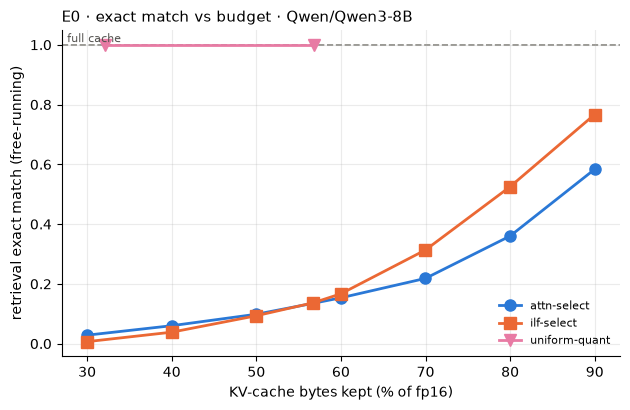

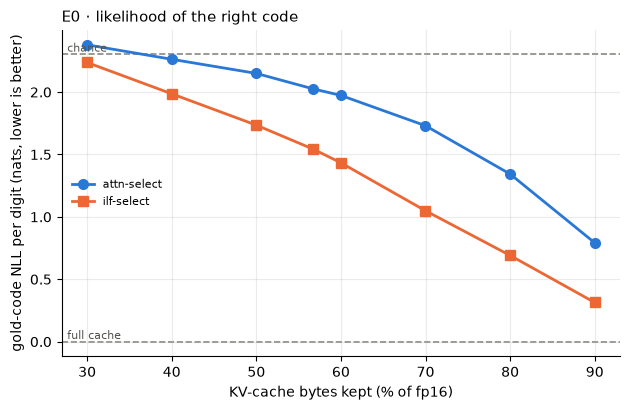

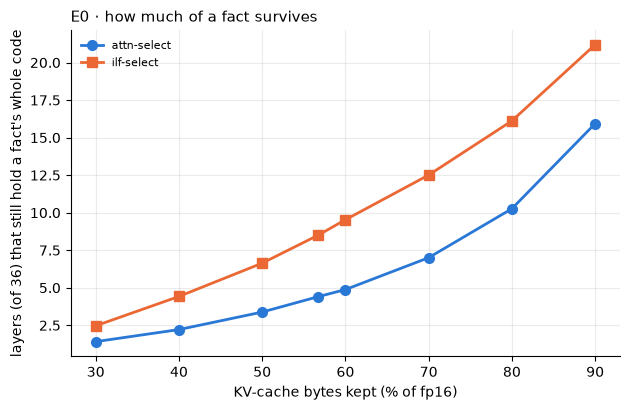

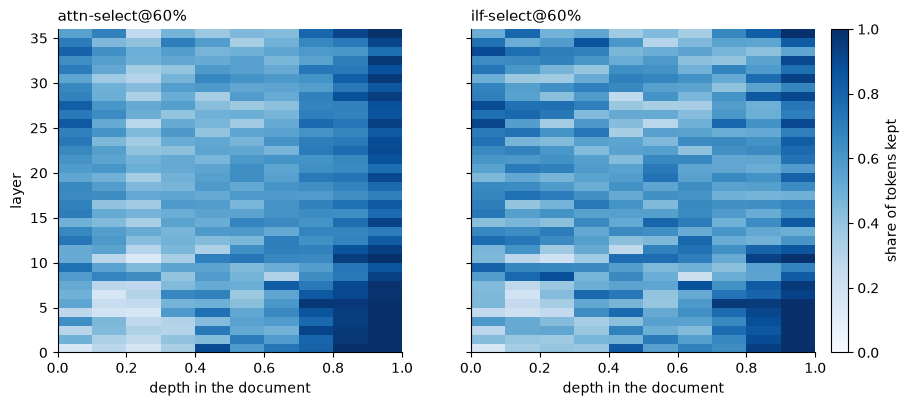

Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e0_paired_ilf_vs_attention.csv


,budget,a,b,metric,n,mean_a,mean_b,diff_b_minus_a,ci_lo,ci_hi,a_better,b_better
0,0.3,attn-select@30%,ilf-select@30%,correct,600,0.028,0.007,-0.022,-0.030,-0.013,15,2
1,0.3,attn-select@30%,ilf-select@30%,tf_exact,600,0.032,0.013,-0.018,-0.030,-0.007,17,6
2,0.3,attn-select@30%,ilf-select@30%,gold_nll,600,2.379,2.238,-0.141,-0.186,-0.096,157,443
3,0.4,attn-select@40%,ilf-select@40%,correct,600,0.060,0.038,-0.022,-0.037,-0.005,20,7
4,0.4,attn-select@40%,ilf-select@40%,tf_exact,600,0.065,0.043,-0.022,-0.037,-0.005,23,10
5,0.4,attn-select@40%,ilf-select@40%,gold_nll,600,2.263,1.987,-0.276,-0.323,-0.235,155,445
6,0.5,attn-select@50%,ilf-select@50%,correct,600,0.098,0.093,-0.005,-0.018,0.008,24,21
7,0.5,attn-select@50%,ilf-select@50%,tf_exact,600,0.100,0.117,0.017,-0.003,0.038,21,31
8,0.5,attn-select@50%,ilf-select@50%,gold_nll,600,2.150,1.735,-0.414,-0.489,-0.345,148,452
9,0.6,attn-select@60%,ilf-select@60%,correct,600,0.153,0.167,0.013,-0.015,0.043,30,38


full-cache tf-exact 1.000; attention selection is in the 20-80% band at budgets [0.7, 0.8, 0.9]
probe budgets for E2, E3, E6: [0.7, 0.9]
E0: 19 arms, 159.6 s per arm (median 158.0 s), 0.84 GPU-hours in total


In [19]:
PROBE_FILE = OUT / "e0" / "probe_budgets.json"


def probe_budgets():
    """Budgets for E2, E3 and E6: the ones E0 picked (read from disk, so they can run in another job)."""
    if not AUTO_PROBE_BUDGETS:
        return list(PROBE_BUDGETS_FALLBACK)
    if PROBE_FILE.exists():
        return json.loads(PROBE_FILE.read_text())["probe_budgets"]
    print(f"WARNING: {PROBE_FILE} does not exist (E0 has not finished); using the fallback {PROBE_BUDGETS_FALLBACK}")
    MANIFEST.set("probe_budgets_fallback", PROBE_BUDGETS_FALLBACK)
    return list(PROBE_BUDGETS_FALLBACK)


if RUN_E0:
    MANIFEST.begin("e0")
    e0_budgets = [*KEEP_GRID, "int8"]
    e0_arms = reference_arms() + [Arm(make_config(f"{fam}@{budget_tag(b)}", "select", b, lam))
                                  for b in e0_budgets for fam, lam in (("attn-select", 0.0), ("ilf-select", LAMBDA))]
    e0_retention = {}
    e0_raw = run_arms(model, tokenizer, e0_arms, exp_docs, "e0", HAYSTACK, generate=True, retention=e0_retention)
    save_table(e0_raw, "e0_budget_sweep_raw")
    e0 = summarize_arms(e0_raw)
    save_table(e0, "e0_budget_sweep")
    display(e0[["method", "kv_bytes_pct", "correct", "digit_acc", "tf_exact", "gold_nll", "needle_kept_frac",
                "code_layers_full", "mean_layer_jaccard"]].round(3))
    tradeoff_plot(e0, "correct", "retrieval exact match (free-running)", f"E0 · exact match vs budget · {MODEL_ID}",
                  "e0_exact")
    e0_sel = e0[e0["kind"] == "select"]
    series_plot(e0_sel, "kv_bytes_pct", "gold_nll", "family", "KV-cache bytes kept (% of fp16)",
                "gold-code NLL per digit (nats, lower is better)", "E0 · likelihood of the right code", "e0_gold_nll",
                refs=[(CHANCE_NLL, "chance"), (full_value(e0, "gold_nll"), "full cache")])
    series_plot(e0_sel, "kv_bytes_pct", "code_layers_full", "family", "KV-cache bytes kept (% of fp16)",
                f"layers (of {N_LAYERS}) that still hold a fact's whole code", "E0 · how much of a fact survives",
                "e0_code_layers")
    # Where in the document does each layer keep tokens? (middle budget of the grid)
    mid = budget_tag(KEEP_GRID[len(KEEP_GRID) // 2])
    fig, axes = panels(2, width=5.2)
    for ax, fam in zip(axes, ("attn-select", "ilf-select")):
        heat = torch.stack(e0_retention[f"{fam}@{mid}"]).mean(0).numpy()
        im = ax.imshow(heat, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1, extent=(0, 1, 0, N_LAYERS))
        style_axis(ax, "depth in the document", "layer" if ax is axes[0] else "", f"{fam}@{mid}", legend=False)
        ax.grid(False)
    fig.colorbar(im, ax=axes, label="share of tokens kept", fraction=0.04, pad=0.02)
    save_show(fig, "e0_retention_by_depth", bbox_inches="tight")
    # Paired comparison at every budget: ILF minus attention on the same questions.
    e0_paired = paired_table(e0_raw, [(f"attn-select@{budget_tag(b)}", f"ilf-select@{budget_tag(b)}", {"budget": str(b)})
                                      for b in e0_budgets], metrics=("correct", "tf_exact", "gold_nll"))
    save_table(e0_paired, "e0_paired_ilf_vs_attention")
    display(e0_paired.round(3))
    # Regression against the first run (documents 0-9, free-running exact match): only meaningful on the
    # first run's model and haystack.
    if MODEL_ID == "Qwen/Qwen2.5-0.5B" and HAYSTACK == "repeat" and not SMOKE:
        first_ten = e0_raw[e0_raw["doc"] < 10].groupby("method")["correct"].mean()
        for name, old in (("full", 0.905), ("quant-int4", 0.835), ("attn-select@int8", 0.150), ("ilf-select@int8", 0.075)):
            print(f"regression {name:>18}: now {first_ten[name]:.3f}, first run {old:.3f}")
    # Budgets where plain attention selection is neither at the floor nor at the ceiling.
    full_acc = full_value(e0, "tf_exact")
    grid = e0[(e0["family"] == "attn-select") & (e0["budget"] != "int8")].assign(b=lambda t: t["budget"].astype(float))
    usable = [float(b) for b in grid[(grid["tf_exact"] > 0.2 * full_acc) & (grid["tf_exact"] < 0.8 * full_acc)]["b"]]
    print(f"full-cache tf-exact {full_acc:.3f}; attention selection is in the 20-80% band at budgets {usable}")
    in_band = bool(usable)
    if not usable:  # nothing inside the band: take the budget closest to half of the full-cache accuracy
        usable = [float(grid.loc[(grid["tf_exact"] - 0.5 * full_acc).abs().idxmin(), "b"])]
        print(f"no grid budget falls in the band (widen KEEP_GRID); using the closest one, {usable}")
    suggested = sorted({min(usable), max(usable)})
    if AUTO_PROBE_BUDGETS:
        save_json(PROBE_FILE, {"probe_budgets": suggested, "in_band": in_band, "full_tf_exact": full_acc,
                               "written": now()})
    print("probe budgets for E2, E3, E6:", probe_budgets())
    MANIFEST.end("e0", probe_budgets=probe_budgets(), seconds=report_seconds(e0_raw, "E0"))

## 11. E5 · Tier split: fewer tokens at high precision, or more tokens at low precision?
In the first run uniform 4-bit quantization (32% of bytes, nothing evicted) beat every method that evicts at the
same bytes. This experiment varies only how a fixed byte budget is split over precision tiers (`tier_split` = share
of the budget for 16 / 8 / 4-bit tokens), from "few tokens at 16 bits" to "as many tokens as possible at 4 bits",
for four rankings: plain attention, ILF, and two random rankings (shared across layers, independent per layer).
If the random rankings match the score-based ones, the scores carry no information about which tokens deserve bits.
Uniform 8 / 4 / 2-bit quantization is included for reference; 2-bit reaches about 19% of bytes without evicting.
The figures plot per-digit accuracy and gold NLL: exact match sits at 0–4% for every evicting arm.

                        full [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 100.0%


                  quant-int8 [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 56.9%


                  quant-int4 [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 32.1%


                  quant-int2 [window]  cached: tf-exact 0.995  digit 0.999  gold NLL 0.00  needle kept 1.00  KV bytes 19.7%


   attention/16-bit only@10% [window]  cached: tf-exact 0.002  digit 0.102  gold NLL 2.69  needle kept 0.06  KV bytes 10.0%


         ilf/16-bit only@10% [window]  cached: tf-exact 0.000  digit 0.094  gold NLL 2.70  needle kept 0.07  KV bytes 10.0%


... (62 outputs left out)

tf_digit_acc


ranking                        attention    ilf  random-shared  \
budget split                                                     
0.1    16-bit only                 0.102  0.094          0.153   
       16/8/4 thirds               0.127  0.151          0.211   
       8-bit only                  0.129  0.143          0.186   
       10% 16-bit, rest 4-bit      0.165  0.210          0.288   
       4-bit only                  0.175  0.221          0.314   
0.2    16-bit only                 0.133  0.157          0.219   
       16/8/4 thirds               0.223  0.316          0.403   
       8-bit only                  0.200  0.274          0.359   
       10% 16-bit, rest 4-bit      0.329  0.517          0.594   
       4-bit only                  0.359  0.580          0.639   
int4   16-bit only                 0.186  0.251          0.334   
       16/8/4 thirds               0.370  0.591          0.655   
       8-bit only                  0.325  0.507          0.575   
       10% 16-bit, rest 4-bit      0.871  0.963          0.936   
       4-bit only                  1.000  1.000          1.000   

ranking                        random-per-layer  
budget split                                     
0.1    16-bit only                        0.166  
       16/8/4 thirds                      0.309  
       8-bit only                         0.268  
       10% 16-bit, rest 4-bit             0.488  
       4-bit only                         0.538  
0.2    16-bit only                        0.329  
       16/8/4 thirds                      0.740  
       8-bit only                         0.654  
       10% 16-bit, rest 4-bit             0.942  
       4-bit only                         0.956  
int4   16-bit only                        0.599  
       16/8/4 thirds                      0.959  
       8-bit only                         0.932  
       10% 16-bit, rest 4-bit             1.000  
       4-bit only                         1.000

gold_nll


ranking                        attention    ilf  random-shared  \
budget split                                                     
0.1    16-bit only                 2.695  2.697          2.566   
       16/8/4 thirds               2.582  2.458          2.566   
       8-bit only                  2.607  2.509          2.585   
       10% 16-bit, rest 4-bit      2.421  2.274          2.512   
       4-bit only                  2.393  2.247          2.523   
0.2    16-bit only                 2.568  2.434          2.565   
       16/8/4 thirds               2.277  2.024          2.479   
       8-bit only                  2.332  2.118          2.539   
       10% 16-bit, rest 4-bit      2.012  1.526          2.297   
       4-bit only                  1.946  1.375          2.178   
int4   16-bit only                 2.352  2.180          2.524   
       16/8/4 thirds               1.910  1.334          2.139   
       8-bit only                  2.034  1.555          2.331   
       10% 16-bit, rest 4-bit      0.549  0.181          0.541   
       4-bit only                  0.000  0.000          0.000   

ranking                        random-per-layer  
budget split                                     
0.1    16-bit only                        2.378  
       16/8/4 thirds                      2.079  
       8-bit only                         2.156  
       10% 16-bit, rest 4-bit             1.696  
       4-bit only                         1.590  
0.2    16-bit only                        2.027  
       16/8/4 thirds                      1.033  
       8-bit only                         1.267  
       10% 16-bit, rest 4-bit             0.301  
       4-bit only                         0.224  
int4   16-bit only                        1.411  
       16/8/4 thirds                      0.212  
       8-bit only                         0.347  
       10% 16-bit, rest 4-bit             0.002  
       4-bit only                         0.000

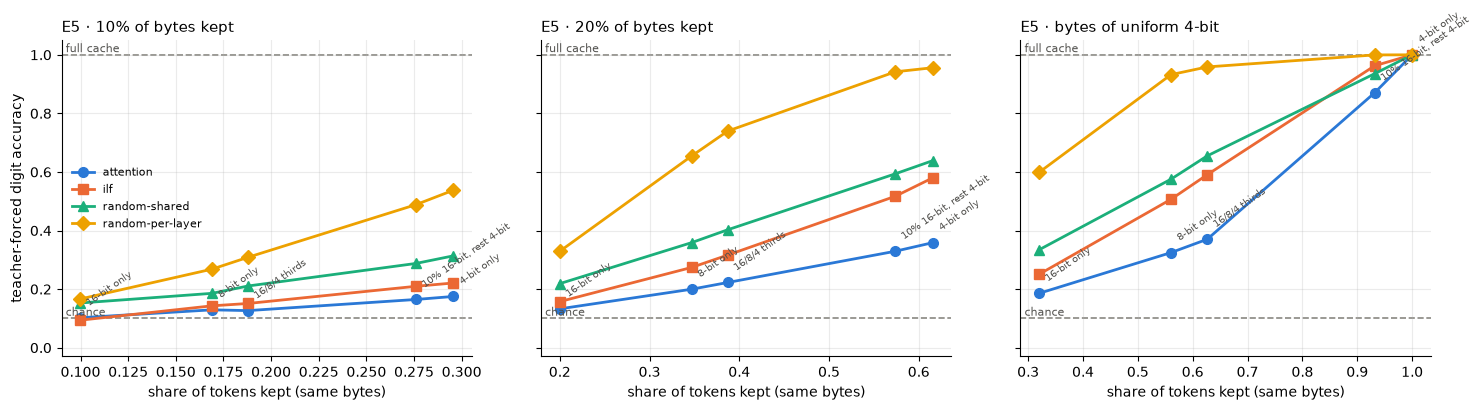

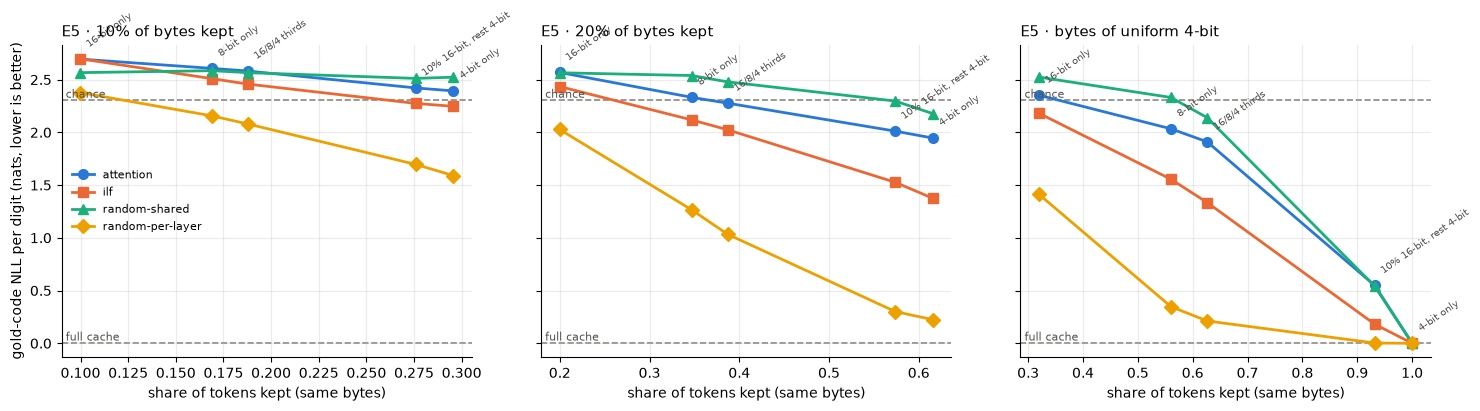

Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e5_paired_vs_attention.csv


,budget,split,ranking,a,b,metric,n,mean_a,mean_b,diff_b_minus_a,ci_lo,ci_hi,a_better,b_better
0,0.1,16-bit only,ilf,attention/16-bit only@10%,ilf/16-bit only@10%,tf_digit_acc,600,0.102,0.094,-0.008,-0.016,-0.000,71,67
2,0.1,16-bit only,random-shared,attention/16-bit only@10%,random-shared/16-bit only@10%,tf_digit_acc,600,0.102,0.153,0.050,0.036,0.064,89,220
4,0.1,16-bit only,random-per-layer,attention/16-bit only@10%,random-per-layer/16-bit only@10%,tf_digit_acc,600,0.102,0.166,0.064,0.050,0.078,72,231
6,0.1,16/8/4 thirds,ilf,attention/16/8/4 thirds@10%,ilf/16/8/4 thirds@10%,tf_digit_acc,600,0.127,0.151,0.024,0.009,0.039,90,146
8,0.1,16/8/4 thirds,random-shared,attention/16/8/4 thirds@10%,random-shared/16/8/4 thirds@10%,tf_digit_acc,600,0.127,0.211,0.084,0.062,0.108,102,285
10,0.1,16/8/4 thirds,random-per-layer,attention/16/8/4 thirds@10%,random-per-layer/16/8/4 thirds@10%,tf_digit_acc,600,0.127,0.309,0.182,0.155,0.210,60,364
12,0.1,8-bit only,ilf,attention/8-bit only@10%,ilf/8-bit only@10%,tf_digit_acc,600,0.129,0.143,0.014,0.001,0.026,97,131
14,0.1,8-bit only,random-shared,attention/8-bit only@10%,random-shared/8-bit only@10%,tf_digit_acc,600,0.129,0.186,0.056,0.038,0.077,110,255
16,0.1,8-bit only,random-per-layer,attention/8-bit only@10%,random-per-layer/8-bit only@10%,tf_digit_acc,600,0.129,0.268,0.139,0.115,0.164,73,332
18,0.1,"10% 16-bit, rest 4-bit",ilf,"attention/10% 16-bit, rest 4-bit@10%","ilf/10% 16-bit, rest 4-bit@10%",tf_digit_acc,600,0.165,0.210,0.045,0.028,0.065,98,188


E5: 64 arms, 32.2 s per arm (median 32.1 s), 0.57 GPU-hours in total


In [20]:
E5_SPLITS = {"16-bit only": (1, 0, 0), "16/8/4 thirds": (1 / 3, 1 / 3, 1 / 3), "8-bit only": (0, 1, 0),
             "10% 16-bit, rest 4-bit": (0.1, 0, 0.9), "4-bit only": (0, 0, 1)}
E5_RANKINGS = {"attention": {}, "ilf": {"lam": LAMBDA}, "random-shared": {"score_mode": "random_shared"},
               "random-per-layer": {"score_mode": "random_layer"}}
if RUN_E5:
    MANIFEST.begin("e5")
    e5_arms = reference_arms({"ranking": "uniform", "split": "uniform"}, bits=(8, 4, 2))
    e5_arms += [Arm(make_config(f"{rank}/{split}@{budget_tag(b)}", "mixed", b, tier_split=shares, **kw),
                    tags={"ranking": rank, "split": split})
                for b in E5_BUDGETS for split, shares in E5_SPLITS.items() for rank, kw in E5_RANKINGS.items()]
    e5_raw = run_arms(model, tokenizer, e5_arms, exp_docs, "e5", HAYSTACK, generate=EXP_GENERATE)
    save_table(e5_raw, "e5_tier_split_raw")
    e5 = summarize_arms(e5_raw, by=["ranking", "split"])
    save_table(e5, "e5_tier_split")
    display(e5[e5["ranking"] == "uniform"][["method", "kv_bytes_pct", "tf_exact", "tf_digit_acc", "gold_nll"]].round(3))
    e5_mixed = e5[e5["kind"] == "mixed"]
    for metric in ("tokens_retained_frac", "tf_digit_acc", "gold_nll"):
        print(metric)
        display(e5_mixed.pivot_table(index=["budget", "split"], columns="ranking", values=metric, sort=False).round(3))
    for metric, ylabel, refs in (
            ("tf_digit_acc", "teacher-forced digit accuracy",
             [(full_value(e5, "tf_digit_acc"), "full cache"), (CHANCE_DIGIT_ACC, "chance")]),
            ("gold_nll", "gold-code NLL per digit (nats, lower is better)",
             [(full_value(e5, "gold_nll"), "full cache"), (CHANCE_NLL, "chance")])):
        fig, axes = panels(len(E5_BUDGETS), width=5.0)
        for ax, b in zip(axes, E5_BUDGETS):
            part = e5_mixed[e5_mixed["budget"] == str(b)]
            draw_series(ax, part, "tokens_retained_frac", metric, "ranking", order=list(E5_RANKINGS), refs=refs)
            for _, r in part[part["ranking"] == "attention"].iterrows():  # name the splits once, on one series
                ax.annotate(r["split"], (r["tokens_retained_frac"], r[metric]), xytext=(3, 7), rotation=35,
                            textcoords="offset points", ha="left", va="bottom", fontsize=7, color=INK_SECONDARY)
            style_axis(ax, "share of tokens kept (same bytes)", ylabel if ax is axes[0] else "",
                       f"E5 · {budget_title(b)}", legend=ax is axes[0], unit=metric == "tf_digit_acc")
        save_show(fig, f"e5_tier_split_{metric}")
    # Each ranking against attention, at the same budget and split.
    e5_paired = paired_table(e5_raw, [(f"attention/{split}@{budget_tag(b)}", f"{rank}/{split}@{budget_tag(b)}",
                                       {"budget": str(b), "split": split, "ranking": rank})
                                      for b in E5_BUDGETS for split in E5_SPLITS for rank in E5_RANKINGS
                                      if rank != "attention"], metrics=("tf_digit_acc", "gold_nll"))
    save_table(e5_paired, "e5_paired_vs_attention")
    display(e5_paired[e5_paired["metric"] == "tf_digit_acc"].round(3))
    MANIFEST.end("e5", seconds=report_seconds(e5_raw, "E5"))

## 12. E2 · Consistency sweep: does retrieval rise with cross-layer agreement?
At each probe budget, selection methods are lined up from most diverse to most consistent across layers, at
identical bytes:
* **ILF** with λ = 4, 1, 0.25, plus two repairs of its formula: `ilf-gated` (no boost for tokens that no layer
  would keep, which otherwise get the largest boost) and a tighter τ.
* **plain attention**, each layer on its own (the baseline).
* **mix α**: `(1−α)·rank_l + α·mean-rank over layers`; α = 1 keeps the same tokens in every layer.
* **lf**: `a·(1 + λ·log(1+d_i))`, the opposite of ILF, boosting tokens that many layers want.
* **random controls**: one random set shared by all layers vs an independent random set per layer. These two keep
  the same number of tokens and differ only in cross-layer agreement.

The figure plots each arm's retrieval against `mean_layer_jaccard`; H1 predicts a rising trend.

                        full [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 100.0%


                 ilf λ=4@70% [window]  cached: tf-exact 0.737  digit 0.921  gold NLL 0.37  needle kept 0.75  KV bytes 70.0%


                 ilf λ=1@70% [window]  cached: tf-exact 0.348  digit 0.693  gold NLL 1.05  needle kept 0.66  KV bytes 70.0%


              ilf λ=0.25@70% [window]  cached: tf-exact 0.252  digit 0.499  gold NLL 1.55  needle kept 0.60  KV bytes 70.0%


           ilf-gated λ=4@70% [window]  cached: tf-exact 0.648  digit 0.892  gold NLL 0.58  needle kept 0.74  KV bytes 70.0%


           ilf-gated λ=1@70% [window]  cached: tf-exact 0.330  digit 0.667  gold NLL 1.12  needle kept 0.65  KV bytes 70.0%


... (25 outputs left out)

           random-shared@90% [window]  cached: tf-exact 0.655  digit 0.906  gold NLL 0.78  needle kept 0.90  KV bytes 90.0%


        random-per-layer@90% [window]  cached: tf-exact 0.997  digit 0.999  gold NLL 0.00  needle kept 0.90  KV bytes 90.0%


Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e2_consistency_raw.csv
Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e2_consistency.csv


,method,group,mean_layer_jaccard,unique_positions_frac,tf_exact,tf_digit_acc,gold_nll,code_layers_full
0,full,reference,1.000,1.000,1.000,1.000,0.000,36.000
1,ilf λ=4@70%,ILF (more diverse),0.587,1.000,0.737,0.921,0.367,22.070
2,ilf λ=1@70%,ILF (more diverse),0.572,1.000,0.348,0.693,1.049,12.505
3,ilf λ=0.25@70%,ILF (more diverse),0.634,1.000,0.252,0.499,1.548,8.425
4,ilf-gated λ=4@70%,ILF (more diverse),0.590,0.994,0.648,0.892,0.585,18.768
5,ilf-gated λ=1@70%,ILF (more diverse),0.576,0.994,0.330,0.667,1.124,11.270
6,ilf-tight-τ λ=1@70%,ILF (more diverse),0.574,1.000,0.318,0.639,1.233,11.473
7,attention@70%,per-layer attention,0.686,0.994,0.220,0.444,1.731,7.002
8,mix α=0.25@70%,more consistent,0.728,0.984,0.202,0.407,1.859,6.217
9,mix α=0.5@70%,more consistent,0.792,0.948,0.187,0.386,1.936,5.238


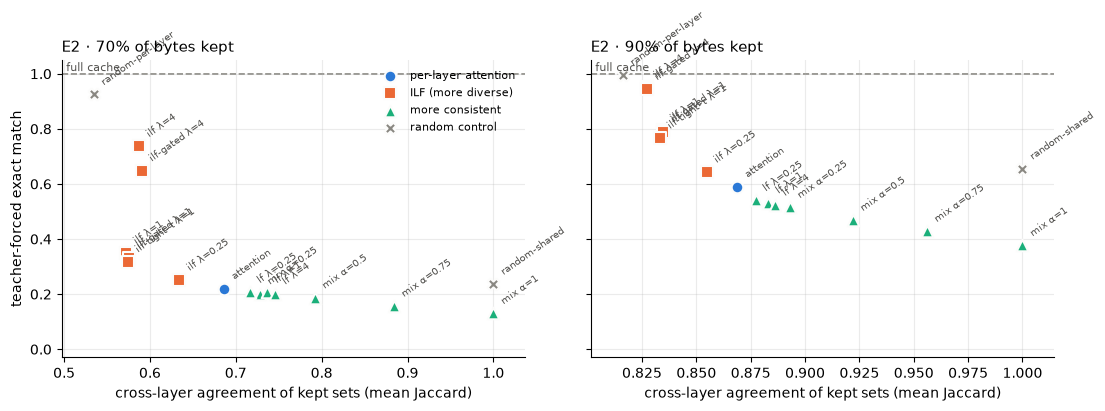

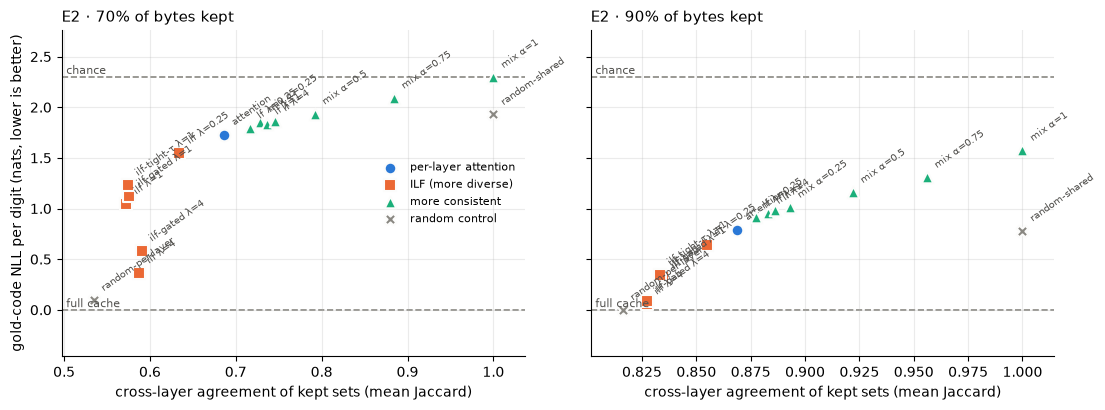

Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e2_paired_vs_attention.csv


,budget,a,b,metric,n,mean_a,mean_b,diff_b_minus_a,ci_lo,ci_hi,a_better,b_better
1,0.7,attention@70%,ilf λ=4@70%,gold_nll,600,1.731,0.367,-1.364,-1.499,-1.213,136,464
3,0.7,attention@70%,ilf λ=1@70%,gold_nll,600,1.731,1.049,-0.681,-0.770,-0.583,165,435
5,0.7,attention@70%,ilf λ=0.25@70%,gold_nll,600,1.731,1.548,-0.183,-0.234,-0.138,181,419
7,0.7,attention@70%,ilf-gated λ=4@70%,gold_nll,600,1.731,0.585,-1.146,-1.284,-1.004,159,441
9,0.7,attention@70%,ilf-gated λ=1@70%,gold_nll,600,1.731,1.124,-0.607,-0.701,-0.513,163,437
11,0.7,attention@70%,ilf-tight-τ λ=1@70%,gold_nll,600,1.731,1.233,-0.498,-0.577,-0.422,189,411
13,0.7,attention@70%,mix α=0.25@70%,gold_nll,600,1.731,1.859,0.128,0.082,0.187,440,160
15,0.7,attention@70%,mix α=0.5@70%,gold_nll,600,1.731,1.936,0.205,0.156,0.261,453,147
17,0.7,attention@70%,mix α=0.75@70%,gold_nll,600,1.731,2.092,0.361,0.300,0.429,459,141
19,0.7,attention@70%,mix α=1@70%,gold_nll,600,1.731,2.296,0.565,0.472,0.663,461,139


E2: 33 arms, 32.3 s per arm (median 32.6 s), 0.30 GPU-hours in total


In [21]:
E2_GROUPS = {"per-layer attention": (SERIES_COLORS[0], "o"), "ILF (more diverse)": (SERIES_COLORS[1], "s"),
             "more consistent": (SERIES_COLORS[2], "^"), "random control": (INK_MUTED, "X")}


def e2_arms_at(b):
    def arm(label, group, lam=0.0, **kw):
        return Arm(select_cfg(label, b, lam, **kw), tags={"arm": label, "group": group})
    diverse, consistent = "ILF (more diverse)", "more consistent"
    return ([arm(f"ilf λ={lam:g}", diverse, lam) for lam in (4.0, 1.0, 0.25)]
            + [arm(f"ilf-gated λ={lam:g}", diverse, lam, score_mode="ilf_gated") for lam in (4.0, 1.0)]
            + [arm("ilf-tight-τ λ=1", diverse, 1.0, tau_quantile=1 - b / 2)]
            + [arm("attention", "per-layer attention")]
            + [arm(f"mix α={a:g}", consistent, score_mode="mix", layer_mix=a) for a in (0.25, 0.5, 0.75, 1.0)]
            + [arm(f"lf λ={lam:g}", consistent, lam, score_mode="lf") for lam in (0.25, 1.0, 4.0)]
            + [arm("random-shared", "random control", score_mode="random_shared"),
               arm("random-per-layer", "random control", score_mode="random_layer")])


def scatter_by_group(ax, df, x, y):
    for group, (color, marker) in E2_GROUPS.items():
        part = df[df["group"] == group]
        ax.scatter(part[x], part[y], s=70, color=color, marker=marker, edgecolors=SURFACE, linewidths=1.5,
                   label=group, zorder=4 if group == "per-layer attention" else 3)
        for _, r in part.iterrows():  # every point is named; the table above carries the exact values
            ax.annotate(r["arm"], (r[x], r[y]), xytext=(4, 5), textcoords="offset points", fontsize=7,
                        color=INK_SECONDARY, rotation=35, ha="left", va="bottom")


if RUN_E2:
    MANIFEST.begin("e2")
    e2_budgets = probe_budgets()
    e2_arms = [Arm(make_config("full", "full"), tags={"arm": "full", "group": "reference"})]
    for b in e2_budgets:
        e2_arms += e2_arms_at(b)
    e2_raw = run_arms(model, tokenizer, e2_arms, exp_docs, "e2", HAYSTACK, generate=EXP_GENERATE)
    save_table(e2_raw, "e2_consistency_raw")
    e2 = summarize_arms(e2_raw, keys=["method", "arm", "group", "budget", "kind"])
    save_table(e2, "e2_consistency")
    display(e2[["method", "group", "mean_layer_jaccard", "unique_positions_frac", "tf_exact", "tf_digit_acc", "gold_nll",
                "code_layers_full"]].round(3))
    for metric, ylabel, refs in (
            ("tf_exact", "teacher-forced exact match", [(full_value(e2, "tf_exact"), "full cache")]),
            ("gold_nll", "gold-code NLL per digit (nats, lower is better)",
             [(CHANCE_NLL, "chance"), (full_value(e2, "gold_nll"), "full cache")])):
        fig, axes = panels(len(e2_budgets))
        for ax, b in zip(axes, e2_budgets):
            scatter_by_group(ax, e2[e2["budget"] == str(b)], "mean_layer_jaccard", metric)
            ax.margins(x=0.08, y=0.2)  # room for the point labels
            draw_refs(ax, refs)
            style_axis(ax, "cross-layer agreement of kept sets (mean Jaccard)", ylabel if ax is axes[0] else "",
                       f"E2 · {budget_title(b)}", legend=ax is axes[0], unit=metric == "tf_exact")
        save_show(fig, f"e2_consistency_{metric}")
    # Every arm against plain attention on the same questions.
    e2_paired = paired_table(e2_raw, [(f"attention@{budget_tag(b)}", arm.cfg.name, {"budget": str(b)})
                                      for b in e2_budgets for arm in e2_arms_at(b) if arm.tags["arm"] != "attention"],
                             metrics=("tf_exact", "gold_nll"))
    save_table(e2_paired, "e2_paired_vs_attention")
    display(e2_paired[e2_paired["metric"] == "gold_nll"].round(3))
    MANIFEST.end("e2", budgets=e2_budgets, seconds=report_seconds(e2_raw, "E2"))

## 13. E1 · Layer coverage: which layers must still hold a fact for retrieval to work?
ILF trades *layers per token* for *more distinct tokens*. This experiment measures what that trade costs, using
the known positions of the facts (an oracle, so not a compression method):
* **Knock-out.** The cache is left complete except that every fact sentence is evicted from all but `m` layers.
  The surviving layers are the lowest `m`, the highest `m`, `m` random layers per fact, or `m` random layers per
  token (the closest picture of what ILF produces).
* **Single-layer scan.** The facts are evicted from one layer at a time, which shows which layers carry retrieval.
  Even layers run first, so a partial run already has a scan at every second layer.
* **Oracle-keep.** Selection at 10% and 20% bytes with the fact tokens ranked first in every layer: the ceiling
  for any query-agnostic token selector at that budget.

If accuracy needs the fact in most layers, counting distinct positions kept in *any* layer (`unique_positions`)
measures the wrong thing, and the useful statistic is layers per token.

                        full [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 100.0%


       knockout-lowest-m0-s0 [window]  cached: tf-exact 0.000  digit 0.060  gold NLL 2.88  needle kept 0.00  KV bytes 91.6%


       knockout-lowest-m3-s0 [window]  cached: tf-exact 0.000  digit 0.061  gold NLL 2.88  needle kept 0.08  KV bytes 92.3%


       knockout-lowest-m6-s0 [window]  cached: tf-exact 0.000  digit 0.055  gold NLL 2.91  needle kept 0.17  KV bytes 93.0%


      knockout-lowest-m12-s0 [window]  cached: tf-exact 0.000  digit 0.056  gold NLL 3.27  needle kept 0.33  KV bytes 94.4%


      knockout-lowest-m18-s0 [window]  cached: tf-exact 0.000  digit 0.105  gold NLL 2.76  needle kept 0.50  KV bytes 95.8%


... (73 outputs left out)

             attn-select@20% [window]  cached: tf-exact 0.008  digit 0.133  gold NLL 2.57  needle kept 0.14  KV bytes 20.0%


             oracle-keep@20% [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 20.0%


Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e1_layer_coverage_raw.csv
Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e1_knockout.csv


scheme,highest,lowest,random_fact,random_token
layers_kept,,,,
0.0,0.000,0.000,0.000,0.000
3.0,0.000,0.000,0.000,0.000
6.0,0.000,0.000,0.010,0.000
12.0,0.000,0.000,0.101,0.097
18.0,0.338,0.000,0.345,0.512
24.0,0.587,0.948,0.641,0.878
30.0,1.000,1.000,0.902,0.987
36.0,1.000,1.000,1.000,1.000


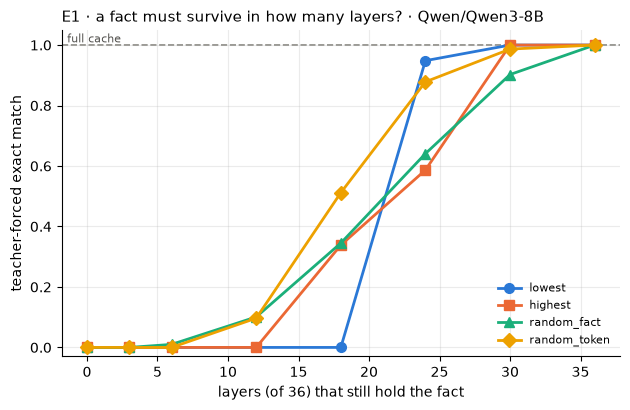

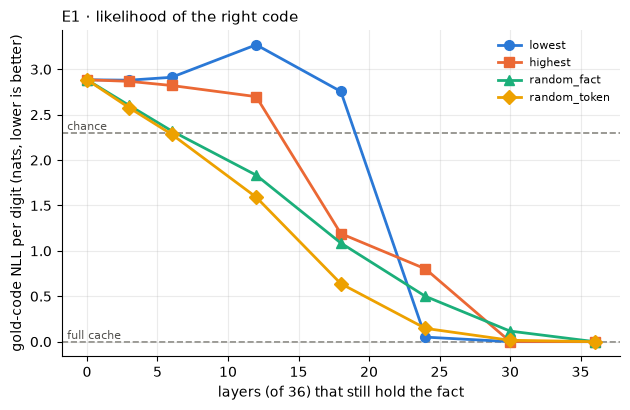

Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e1_single_layer.csv


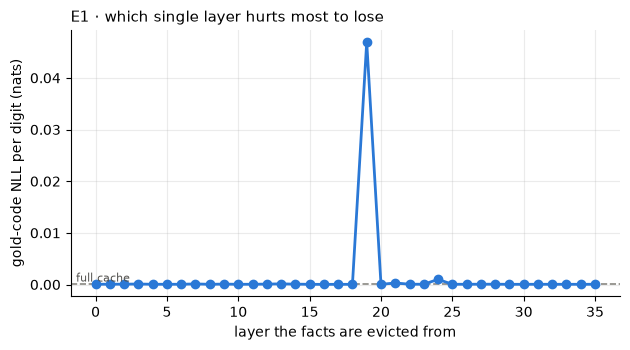

Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e1_oracle_keep.csv


,budget,scheme,tf_exact,tf_digit_acc,gold_nll,needle_kept_frac,kv_bytes_pct
0,0.1,plain attention,0.002,0.102,2.695,0.065,9.986
1,0.1,facts ranked first,1.000,1.000,0.000,1.000,9.986
2,0.2,plain attention,0.008,0.133,2.568,0.136,19.986
3,0.2,facts ranked first,1.000,1.000,0.000,1.000,19.986


full cache: tf-exact 1.000, gold NLL 0.00
E1: 81 arms, 33.1 s per arm (median 33.3 s), 0.75 GPU-hours in total


In [22]:
if RUN_E1:
    MANIFEST.begin("e1")
    m_grid = sorted({round(N_LAYERS * f) for f in (0, 1 / 12, 1 / 6, 1 / 3, 1 / 2, 2 / 3, 5 / 6, 1)})
    e1_arms = [Arm(make_config("full", "full"), tags={"experiment": "reference", "scheme": "full"})]
    for scheme, seeds in (("lowest", [0]), ("highest", [0]), ("random_fact", [0, 1]), ("random_token", [0])):
        for m in m_grid:
            for seed in seeds:
                e1_arms.append(Arm(make_config(f"knockout-{scheme}-m{m}-s{seed}", "full"), plan=knockout_plan(scheme, m, seed),
                                   tags={"experiment": "knockout", "scheme": scheme, "layers_kept": m, "seed": seed}))
    for layer in [*range(0, N_LAYERS, 2), *range(1, N_LAYERS, 2)]:
        e1_arms.append(Arm(make_config(f"knockout-layer{layer}", "full"), plan=knockout_plan("single", layer),
                           tags={"experiment": "single_layer", "scheme": "single", "layer": layer}))
    for b in (0.1, 0.2):
        e1_arms.append(Arm(select_cfg("attn-select", b), tags={"experiment": "oracle", "scheme": "plain attention"}))
        e1_arms.append(Arm(select_cfg("oracle-keep", b), plan=protect_plan,
                           tags={"experiment": "oracle", "scheme": "facts ranked first"}))
    e1_raw = run_arms(model, tokenizer, e1_arms, exp_docs, "e1", HAYSTACK, generate=EXP_GENERATE)
    save_table(e1_raw, "e1_layer_coverage_raw")
    e1_full = e1_raw[e1_raw["experiment"] == "reference"]
    full_refs = lambda metric: [(e1_full[metric].astype(float).mean(), "full cache")]
    knock = summarize_arms(e1_raw[e1_raw["experiment"] == "knockout"], keys=["scheme", "layers_kept"])
    save_table(knock, "e1_knockout")
    display(knock.pivot(index="layers_kept", columns="scheme", values="tf_exact").round(3))
    series_plot(knock, "layers_kept", "tf_exact", "scheme", f"layers (of {N_LAYERS}) that still hold the fact",
                "teacher-forced exact match", f"E1 · a fact must survive in how many layers? · {MODEL_ID}",
                "e1_knockout_exact", refs=full_refs("tf_exact"), unit=True)
    series_plot(knock, "layers_kept", "gold_nll", "scheme", f"layers (of {N_LAYERS}) that still hold the fact",
                "gold-code NLL per digit (nats, lower is better)", "E1 · likelihood of the right code",
                "e1_knockout_nll", refs=[(CHANCE_NLL, "chance"), *full_refs("gold_nll")])
    scan = summarize_arms(e1_raw[e1_raw["experiment"] == "single_layer"], keys=["layer"]).sort_values("layer")
    save_table(scan, "e1_single_layer")
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    ax.plot(scan["layer"], scan["gold_nll"], color=SERIES_COLORS[0], marker="o", lw=2, ms=6)
    draw_refs(ax, full_refs("gold_nll"))
    style_axis(ax, "layer the facts are evicted from", "gold-code NLL per digit (nats)",
               "E1 · which single layer hurts most to lose", legend=False)
    save_show(fig, "e1_single_layer")
    oracle = summarize_arms(e1_raw[e1_raw["experiment"] == "oracle"], keys=["budget", "scheme"])
    save_table(oracle, "e1_oracle_keep")
    display(oracle[["budget", "scheme", "tf_exact", "tf_digit_acc", "gold_nll", "needle_kept_frac", "kv_bytes_pct"]].round(3))
    print(f"full cache: tf-exact {full_refs('tf_exact')[0][0]:.3f}, gold NLL {full_refs('gold_nll')[0][0]:.2f}")
    MANIFEST.end("e1", seconds=report_seconds(e1_raw, "E1"))

## 14. E3 · Scoring signal: what must the selector see?
ILF only re-weights the attention scores it is given, so this experiment varies where those scores come from and
keeps everything else fixed. The compressed cache always holds the document only; any extra tokens are used for
scoring and then dropped.

| Signal | Scores are the attention from … |
|---|---|
| `window` | the last 32 document tokens (the default) |
| `all_queries` | every later document token, averaged over the tokens that can see each key (H2O-style) |
| `probe` | a fixed, task-agnostic instruction appended after the document |
| `reconstruct` | the document read a second time after "Repeat the text above", max over queries. A simplified version of KVzip's query-agnostic scoring ([arXiv 2505.23416](https://arxiv.org/abs/2505.23416)), not a reimplementation |
| question (same) | the very question that is then asked: query-aware compression, not reusable |
| question (different) | a question about *another* fact: a query-aware cache reused for a new question, the case the proposal is about |

Each signal is combined with plain attention selection, ILF (λ = `LAMBDA`) and the consistent selector (one kept
set for all layers). ILF's fairest test is the "question (different)" row. Question-scored arms compress each
document once per scoring question (every second fact), so each costs several ordinary arms.

                        full [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 100.0%


        attention/window@70% [window]  cached: tf-exact 0.220  digit 0.444  gold NLL 1.73  needle kept 0.57  KV bytes 70.0%


              ilf/window@70% [window]  cached: tf-exact 0.348  digit 0.693  gold NLL 1.05  needle kept 0.66  KV bytes 70.0%


       consistent/window@70% [window]  cached: tf-exact 0.130  digit 0.353  gold NLL 2.30  needle kept 0.53  KV bytes 70.0%


   attention/all_queries@70% [all_queries]  cached: tf-exact 0.727  digit 0.845  gold NLL 0.53  needle kept 0.75  KV bytes 70.0%


         ilf/all_queries@70% [all_queries]  cached: tf-exact 0.517  digit 0.837  gold NLL 0.60  needle kept 0.64  KV bytes 70.0%


... (27 outputs left out)

gold_nll


selector                     attention    ilf  consistent
budget signal                                            
0.7    all_queries               0.525  0.599       1.464
       probe                     0.002  0.011       0.000
       question (different)      0.000  0.000       0.000
       question (same)           0.000  0.000       0.000
       reconstruct               2.024  0.000       2.820
       window                    1.731  1.049       2.296
0.9    all_queries               0.000  0.026       0.212
       probe                     0.000  0.000       0.000
       question (different)      0.000  0.000       0.000
       question (same)           0.000  0.000       0.000
       reconstruct               0.755  0.000       2.294
       window                    0.793  0.314       1.577

code_layers_full


selector                     attention     ilf  consistent
budget signal                                             
0.7    all_queries              17.740  18.923       16.80
       probe                    28.040  25.168       36.00
       question (different)     31.821  29.801       36.00
       question (same)          32.213  30.277       36.00
       reconstruct               6.948  22.400        0.00
       window                    7.002  12.505        4.02
0.9    all_queries              29.300  26.532       31.20
       probe                    33.157  32.082       36.00
       question (different)     34.393  33.752       36.00
       question (same)          34.623  34.067       36.00
       reconstruct              16.573  24.590        0.72
       window                   15.927  21.183       11.58

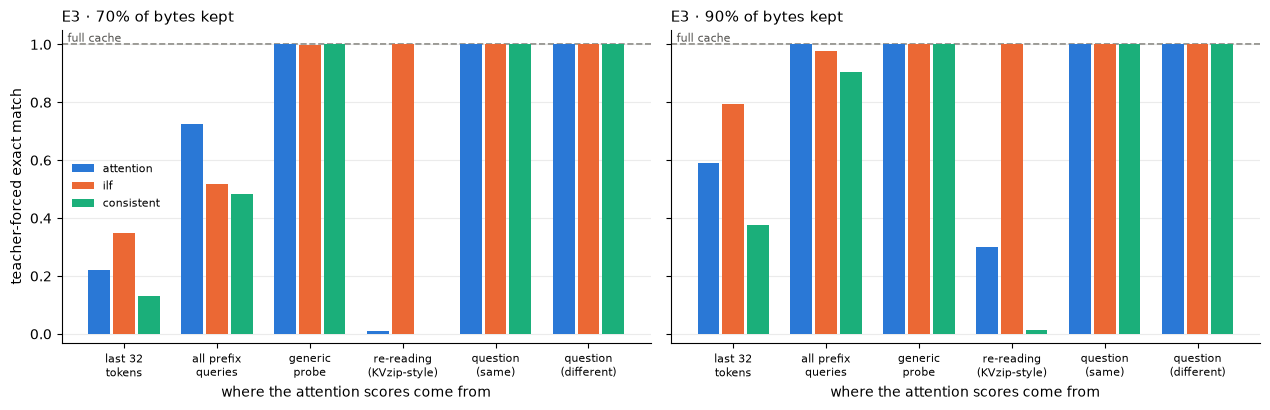

E3: 31 arms, 66.5 s per arm (median 43.0 s), 0.57 GPU-hours in total


In [23]:
E3_SIGNAL_LABELS = {"window": "last 32\ntokens", "all_queries": "all prefix\nqueries", "probe": "generic\nprobe",
                    "reconstruct": "re-reading\n(KVzip-style)", "question (same)": "question\n(same)",
                    "question (different)": "question\n(different)"}
if RUN_E3:
    MANIFEST.begin("e3")
    e3_budgets = probe_budgets()
    e3_signals = ["window", "all_queries", "probe", "reconstruct", "query"]
    longest = max(len(tokenizer(doc).input_ids) for doc, _ in exp_docs)
    if 2 * longest + 32 > getattr(model.config, "max_position_embeddings", 0):
        e3_signals.remove("reconstruct")
        print("Skipping 'reconstruct': two copies of the document do not fit the model's context.")
    e3_selectors = {"attention": {}, "ilf": {"lam": LAMBDA}, "consistent": {"score_mode": "mix", "layer_mix": 1.0}}
    e3_arms = [Arm(make_config("full", "full"), tags={"selector": "full"})]
    e3_arms += [Arm(select_cfg(f"{sel}/{sig}", b, **kw), scoring=sig, tags={"selector": sel})
                for b in e3_budgets for sig in e3_signals for sel, kw in e3_selectors.items()]
    e3_raw = run_arms(model, tokenizer, e3_arms, exp_docs, "e3", HAYSTACK, generate=EXP_GENERATE)
    e3_raw["signal"] = e3_raw["scoring"]
    e3_raw.loc[e3_raw["query_match"] == True, "signal"] = "question (same)"       # noqa: E712
    e3_raw.loc[e3_raw["query_match"] == False, "signal"] = "question (different)"  # noqa: E712
    save_table(e3_raw, "e3_scoring_signal_raw")
    e3 = summarize_arms(e3_raw, keys=["budget", "signal", "selector", "kind"])
    save_table(e3, "e3_scoring_signal")
    e3_sel = e3[e3["kind"] == "select"]
    order = [s for s in E3_SIGNAL_LABELS if s in set(e3_sel["signal"])]
    for metric in ("tf_exact", "gold_nll", "code_layers_full"):
        print(metric)
        display(e3_sel.pivot_table(index=["budget", "signal"], columns="selector", values=metric)
                .reindex(columns=list(e3_selectors)).round(3))
    fig, axes = panels(len(e3_budgets), width=6.4)
    for ax, b in zip(axes, e3_budgets):
        table = (e3_sel[e3_sel["budget"] == str(b)].pivot(index="signal", columns="selector", values="tf_exact")
                 .reindex(index=order, columns=list(e3_selectors)))
        table.index = [E3_SIGNAL_LABELS[s] for s in table.index]
        grouped_bars(ax, table, SERIES_COLORS, refs=[(full_value(e3, "tf_exact"), "full cache")])
        style_axis(ax, "where the attention scores come from", "teacher-forced exact match" if ax is axes[0] else "",
                   f"E3 · {budget_title(b)}", legend=ax is axes[0], unit=True)
        ax.grid(axis="x", visible=False)
    save_show(fig, "e3_scoring_signal")
    MANIFEST.end("e3", budgets=e3_budgets, seconds=report_seconds(e3_raw, "E3"))

## 15. E4 · Haystack: does natural prose change the picture?
The first run's documents repeat twelve filler sentences a few hundred times. Repeated text may soak up the
scoring window's attention and push the unique fact tokens out of every layer's top-k. The same facts, at the same
depths, are hidden in non-repeating, digit-free WikiText prose, and the budget sweep is repeated on both haystacks
for plain attention, ILF and consistent selection. Outputs include the fact-eviction ratio (how often fact tokens
are evicted relative to an average token; 1 = no preference) and paired tables against attention.

--- repeated filler: 3294 tokens in document 0 ---
                        full [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 100.0%


                  quant-int8 [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 56.9%


                  quant-int4 [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 32.1%


             attn-select@10% [window]  cached: tf-exact 0.050  digit 0.144  gold NLL 2.53  needle kept 0.08  KV bytes 10.0%


              ilf-select@10% [window]  cached: tf-exact 0.010  digit 0.142  gold NLL 2.54  needle kept 0.10  KV bytes 10.0%


       consistent-select@10% [window]  cached: tf-exact 0.053  digit 0.148  gold NLL 2.63  needle kept 0.10  KV bytes 10.0%


... (55 outputs left out)

Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e4_haystack_raw.csv
Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e4_haystack.csv


haystack                  natural prose  repeated filler
series            budget                                
attn-select       0.1             0.002            0.050
                  0.2             0.008            0.083
                  0.3             0.032            0.165
                  0.4             0.065            0.247
                  0.5             0.100            0.352
                  0.6             0.155            0.493
                  0.7             0.220            0.642
                  0.8             0.377            0.848
                  0.9             0.590            0.973
consistent-select 0.1             0.000            0.053
                  0.2             0.010            0.090
                  0.3             0.023            0.167
                  0.4             0.038            0.260
                  0.5             0.063            0.332
                  0.6             0.098            0.442
                  0.7             0.130            0.630
                  0.8             0.205            0.827
                  0.9             0.377            0.972
full              1.0             1.000            1.000
ilf-select        0.1             0.000            0.010
                  0.2             0.002            0.050
                  0.3             0.013            0.065
                  0.4             0.043            0.108
                  0.5             0.117            0.190
                  0.6             0.192            0.315
                  0.7             0.348            0.532
                  0.8             0.545            0.790
                  0.9             0.795            0.983
uniform-quant     1.0             1.000            1.000

fact-eviction ratio (1 = facts evicted as often as an average token)


budget                              0.1   0.2   0.3   0.4   0.5   0.6   0.7  \
haystack        family                                                        
natural prose   attn-select        1.04  1.08  1.12  1.18  1.24  1.32  1.42   
                consistent-select  1.04  1.09  1.15  1.21  1.30  1.41  1.56   
                ilf-select         1.04  1.05  1.06  1.06  1.06  1.09  1.14   
repeated filler attn-select        1.02  1.01  0.95  0.88  0.79  0.70  0.60   
                consistent-select  1.00  1.00  0.97  0.90  0.75  0.58  0.38   
                ilf-select         1.00  0.95  0.97  1.00  1.01  1.00  0.95   

budget                              0.8   0.9  
haystack        family                         
natural prose   attn-select        1.58  1.88  
                consistent-select  1.81  2.20  
                ilf-select         1.26  1.52  
repeated filler attn-select        0.51  0.40  
                consistent-select  0.19  0.06  
                ilf-select         0.83  0.63

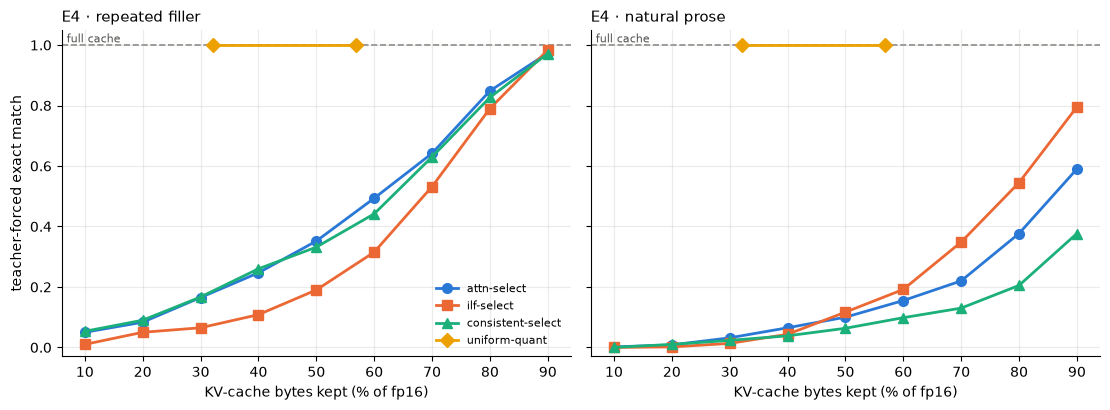

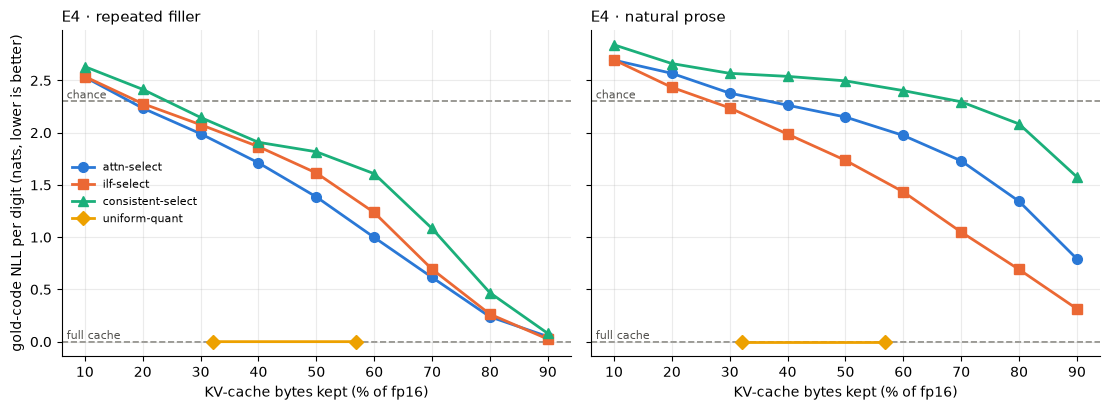

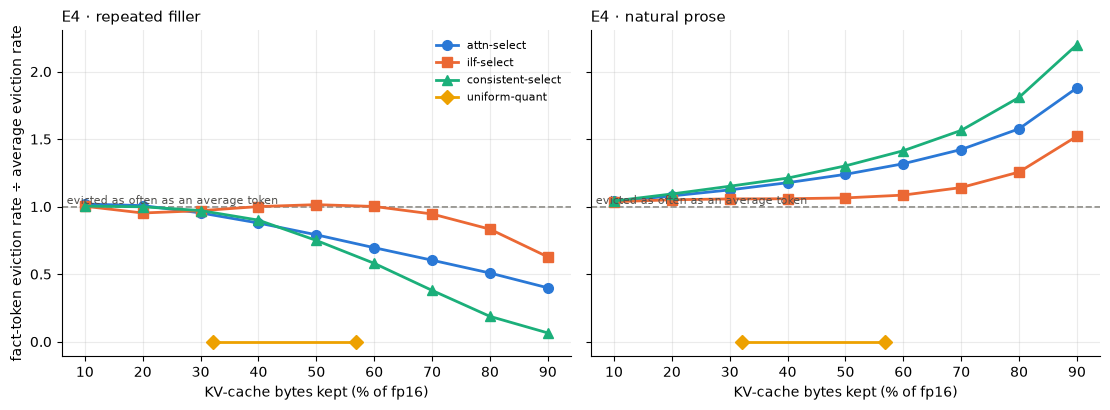

Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e4_paired_vs_attention.csv


,haystack,budget,a,b,metric,n,mean_a,mean_b,diff_b_minus_a,ci_lo,ci_hi,a_better,b_better
1,repeated filler,0.1,attn-select@10%,ilf-select@10%,tf_digit_acc,600,0.144,0.142,-0.002,-0.012,0.008,98,115
4,repeated filler,0.1,attn-select@10%,consistent-select@10%,tf_digit_acc,600,0.144,0.148,0.004,-0.008,0.016,80,83
7,repeated filler,0.2,attn-select@20%,ilf-select@20%,tf_digit_acc,600,0.230,0.218,-0.013,-0.028,0.002,139,165
10,repeated filler,0.2,attn-select@20%,consistent-select@20%,tf_digit_acc,600,0.230,0.216,-0.015,-0.030,0.001,114,89
13,repeated filler,0.3,attn-select@30%,ilf-select@30%,tf_digit_acc,600,0.315,0.300,-0.015,-0.041,0.010,166,198
16,repeated filler,0.3,attn-select@30%,consistent-select@30%,tf_digit_acc,600,0.315,0.309,-0.006,-0.020,0.008,119,104
19,repeated filler,0.4,attn-select@40%,ilf-select@40%,tf_digit_acc,600,0.416,0.378,-0.038,-0.063,-0.013,211,190
22,repeated filler,0.4,attn-select@40%,consistent-select@40%,tf_digit_acc,600,0.416,0.396,-0.021,-0.035,-0.008,125,95
25,repeated filler,0.5,attn-select@50%,ilf-select@50%,tf_digit_acc,600,0.559,0.476,-0.082,-0.113,-0.054,239,144
28,repeated filler,0.5,attn-select@50%,consistent-select@50%,tf_digit_acc,600,0.559,0.516,-0.043,-0.058,-0.026,165,90


E4: 60 arms, 31.5 s per arm (median 31.5 s), 0.53 GPU-hours in total


In [24]:
E4_FAMILIES = {"attn-select": {}, "ilf-select": {"lam": LAMBDA}, "consistent-select": {"score_mode": "mix", "layer_mix": 1.0}}
if RUN_E4:
    MANIFEST.begin("e4")
    e4_budgets = sorted({0.1, 0.2, *KEEP_GRID})
    parts = []
    for hay in ("repeat", "natural"):
        tags = {"haystack": HAYSTACK_LABEL[hay]}
        arms = reference_arms(tags) + [Arm(select_cfg(fam, b, **kw), tags=tags)
                                       for b in e4_budgets for fam, kw in E4_FAMILIES.items()]
        print(f"--- {HAYSTACK_LABEL[hay]}: {len(tokenizer(docs_for(hay)[0][0]).input_ids)} tokens in document 0 ---")
        parts.append(run_arms(model, tokenizer, arms, docs_for(hay), "e4", hay, generate=EXP_GENERATE))
    e4_raw = pd.concat(parts, ignore_index=True)
    save_table(e4_raw, "e4_haystack_raw")
    e4 = add_eviction_ratio(summarize_arms(e4_raw, by=["haystack"]))
    e4["series"] = e4.apply(plot_family, axis=1)
    save_table(e4, "e4_haystack")
    display(e4.pivot_table(index=["series", "budget"], columns="haystack", values="tf_exact").round(3))
    print("fact-eviction ratio (1 = facts evicted as often as an average token)")
    display(e4[e4["kind"] == "select"].pivot_table(index=["haystack", "family"], columns="budget",
                                                   values="evict_ratio").round(2))
    for metric, ylabel in (("tf_exact", "teacher-forced exact match"),
                           ("gold_nll", "gold-code NLL per digit (nats, lower is better)"),
                           ("evict_ratio", "fact-token eviction rate ÷ average eviction rate")):
        fig, axes = panels(2)
        for ax, hay in zip(axes, ("repeated filler", "natural prose")):
            part = e4[e4["haystack"] == hay]
            if metric == "evict_ratio":
                refs = [(1.0, "evicted as often as an average token")]
            else:
                refs = [(full_value(part, metric), "full cache")] + ([(CHANCE_NLL, "chance")] if metric == "gold_nll" else [])
            draw_series(ax, part[part["kind"] != "full"], "kv_bytes_pct", metric, "series",
                        order=[*E4_FAMILIES, "uniform-quant"], refs=refs)
            style_axis(ax, "KV-cache bytes kept (% of fp16)", ylabel if ax is axes[0] else "", f"E4 · {hay}",
                       legend=ax is axes[0], unit=metric == "tf_exact")
        save_show(fig, f"e4_haystack_{metric}")
    e4_paired = pd.concat([
        paired_table(e4_raw[e4_raw["haystack"] == hay],
                     [(f"attn-select@{budget_tag(b)}", f"{fam}@{budget_tag(b)}", {"haystack": hay, "budget": str(b)})
                      for b in e4_budgets for fam in E4_FAMILIES if fam != "attn-select"])
        for hay in ("repeated filler", "natural prose")], ignore_index=True)
    save_table(e4_paired, "e4_paired_vs_attention")
    display(e4_paired[e4_paired["metric"] == "tf_digit_acc"].round(3))
    MANIFEST.end("e4", seconds=report_seconds(e4_raw, "E4"))

## 16. E6 · Position and content diversity
Two selectors that diversify along a different axis than ILF, compared with plain attention, ILF and consistent
selection on both haystacks:
* **segment**: the document is cut into `n_segments` equal blocks and every block keeps the same share of its
  tokens (ranked by attention inside the block). This targets the recency concentration seen in the first run.
* **idf**: `a·(1 + λ·log(M / count))`, where `count` is how often the token's id occurs in the document: the literal
  tf-idf analogue, rare tokens are boosted.

On the repeated-filler haystack the fact tokens are almost the only rare tokens, so `idf` is close to an oracle there
by construction; only its result on natural prose is evidence.

--- repeated filler ---
                        full [window]  cached: tf-exact 1.000  digit 1.000  gold NLL 0.00  needle kept 1.00  KV bytes 100.0%


               attention@20% [window]  cached: tf-exact 0.083  digit 0.230  gold NLL 2.24  needle kept 0.19  KV bytes 20.0%


                 ilf λ=1@20% [window]  cached: tf-exact 0.050  digit 0.218  gold NLL 2.28  needle kept 0.24  KV bytes 20.0%


              consistent@20% [window]  cached: tf-exact 0.090  digit 0.216  gold NLL 2.41  needle kept 0.20  KV bytes 20.0%


                 segment@20% [window]  cached: tf-exact 0.012  digit 0.192  gold NLL 2.49  needle kept 0.25  KV bytes 20.0%


               idf λ=0.5@20% [window]  cached: tf-exact 0.127  digit 0.279  gold NLL 2.09  needle kept 0.23  KV bytes 20.0%


... (42 outputs left out)

code_layers_full


budget                        0.2     0.7     0.9
haystack        arm                              
repeated filler attention   3.385  21.213  30.895
                ilf λ=1     3.632  18.320  29.092
                consistent  2.940  20.640  34.320
                segment     1.890  20.063  30.107
                idf λ=0.5   4.223  24.947  33.232
                idf λ=1     4.388  25.625  33.645
                idf λ=2     4.475  26.088  33.915
natural prose   attention   0.762   7.002  15.927
                ilf λ=1     1.128  12.505  21.183
                consistent  0.120   4.020  11.580
                segment     0.048   4.477  12.487
                idf λ=0.5   0.693   6.740  15.995
                idf λ=1     0.685   6.780  16.355
                idf λ=2     0.680   6.820  16.642

evict_ratio


budget                        0.2    0.7    0.9
haystack        arm                            
repeated filler attention   1.008  0.603  0.399
                ilf λ=1     0.953  0.946  0.628
                consistent  0.999  0.380  0.065
                segment     0.940  0.517  0.386
                idf λ=0.5   0.958  0.511  0.313
                idf λ=1     0.950  0.504  0.310
                idf λ=2     0.944  0.500  0.310
natural prose   attention   1.079  1.423  1.879
                ilf λ=1     1.051  1.141  1.521
                consistent  1.094  1.564  2.199
                segment     1.101  1.492  2.155
                idf λ=0.5   1.119  1.576  2.050
                idf λ=1     1.124  1.590  2.040
                idf λ=2     1.127  1.599  2.027

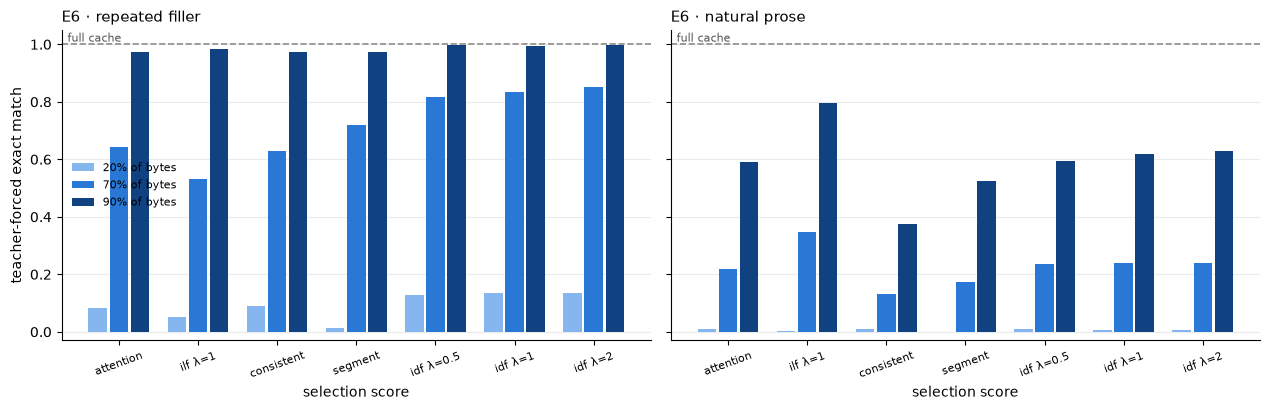

Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/e6_paired_vs_attention.csv


,haystack,budget,a,b,metric,n,mean_a,mean_b,diff_b_minus_a,ci_lo,ci_hi,a_better,b_better
0,repeated filler,0.2,attention@20%,ilf λ=1@20%,tf_exact,600,0.083,0.050,-0.033,-0.045,-0.022,22,2
3,repeated filler,0.2,attention@20%,consistent@20%,tf_exact,600,0.083,0.090,0.007,-0.008,0.023,8,12
6,repeated filler,0.2,attention@20%,segment@20%,tf_exact,600,0.083,0.012,-0.072,-0.083,-0.060,46,3
9,repeated filler,0.2,attention@20%,idf λ=0.5@20%,tf_exact,600,0.083,0.127,0.043,0.027,0.062,2,28
12,repeated filler,0.2,attention@20%,idf λ=1@20%,tf_exact,600,0.083,0.133,0.050,0.032,0.070,1,31
15,repeated filler,0.2,attention@20%,idf λ=2@20%,tf_exact,600,0.083,0.133,0.050,0.032,0.072,1,31
18,repeated filler,0.7,attention@70%,ilf λ=1@70%,tf_exact,600,0.642,0.532,-0.110,-0.147,-0.075,91,25
21,repeated filler,0.7,attention@70%,consistent@70%,tf_exact,600,0.642,0.630,-0.012,-0.048,0.025,49,42
24,repeated filler,0.7,attention@70%,segment@70%,tf_exact,600,0.642,0.720,0.078,0.047,0.113,66,113
27,repeated filler,0.7,attention@70%,idf λ=0.5@70%,tf_exact,600,0.642,0.817,0.175,0.143,0.203,1,106


E6: 44 arms, 31.2 s per arm (median 31.9 s), 0.38 GPU-hours in total


In [25]:
E6_ARMS = {"attention": {}, "ilf λ=1": {"lam": 1.0}, "consistent": {"score_mode": "mix", "layer_mix": 1.0},
           "segment": {"score_mode": "segment"}, "idf λ=0.5": {"score_mode": "idf", "lam": 0.5},
           "idf λ=1": {"score_mode": "idf", "lam": 1.0}, "idf λ=2": {"score_mode": "idf", "lam": 2.0}}
if RUN_E6:
    MANIFEST.begin("e6")
    e6_budgets = sorted({0.2, *probe_budgets()})[:3]
    parts = []
    for hay in ("repeat", "natural"):
        label = HAYSTACK_LABEL[hay]
        arms = [Arm(make_config("full", "full"), tags={"haystack": label, "arm": "full"})]
        arms += [Arm(select_cfg(name, b, **kw), tags={"haystack": label, "arm": name})
                 for b in e6_budgets for name, kw in E6_ARMS.items()]
        print(f"--- {label} ---")
        parts.append(run_arms(model, tokenizer, arms, docs_for(hay), "e6", hay, generate=EXP_GENERATE))
    e6_raw = pd.concat(parts, ignore_index=True)
    save_table(e6_raw, "e6_content_diversity_raw")
    e6 = add_eviction_ratio(summarize_arms(e6_raw, keys=["haystack", "arm", "budget", "kind"]))
    save_table(e6, "e6_content_diversity")
    e6_sel = e6[e6["kind"] == "select"]
    for metric in ("tf_exact", "gold_nll", "code_layers_full", "evict_ratio"):
        print(metric)
        display(e6_sel.pivot_table(index=["haystack", "arm"], columns="budget", values=metric, sort=False).round(3))
    fig, axes = panels(2, width=6.4)
    for ax, hay in zip(axes, ("repeated filler", "natural prose")):
        part = e6_sel[e6_sel["haystack"] == hay]
        table = part.pivot(index="arm", columns="budget", values="tf_exact").reindex(
            index=list(E6_ARMS), columns=[str(b) for b in e6_budgets])
        table.columns = [f"{budget_tag(b)} of bytes" for b in e6_budgets]
        grouped_bars(ax, table, ORDINAL_BLUES, refs=[(full_value(e6[e6["haystack"] == hay], "tf_exact"), "full cache")])
        style_axis(ax, "selection score", "teacher-forced exact match" if ax is axes[0] else "", f"E6 · {hay}",
                   legend=ax is axes[0], unit=True)
        ax.grid(axis="x", visible=False)
        ax.tick_params(axis="x", labelrotation=20)
    save_show(fig, "e6_content_diversity")
    e6_paired = pd.concat([
        paired_table(e6_raw[e6_raw["haystack"] == hay],
                     [(f"attention@{budget_tag(b)}", f"{name}@{budget_tag(b)}", {"haystack": hay, "budget": str(b)})
                      for b in e6_budgets for name in E6_ARMS if name != "attention"])
        for hay in ("repeated filler", "natural prose")], ignore_index=True)
    save_table(e6_paired, "e6_paired_vs_attention")
    display(e6_paired[e6_paired["metric"] == "tf_exact"].round(3))
    MANIFEST.end("e6", budgets=e6_budgets, seconds=report_seconds(e6_raw, "E6"))

## 17. Memory and decode latency
Workload: batch `BENCH_BATCH` × `BENCH_SEQ_LEN` tokens, `BENCH_DECODE_TOKENS` timed decode steps. Methods: the first
run's 19 plus uniform 2-bit and consistent selection at 10% and 20%, 22 in all. In the first run the order of the
methods set the latency numbers (the first ones measured 46–97 ms/token, later ones 27–33), so the protocol is:

1. run in a fresh process with nothing else on the GPU (`LANE = "bench"`);
2. one untimed pass over every method, to warm kernels and the allocator (repeated on every restart);
3. `BENCH_REPEATS` repeats, each in a different shuffled order (fixed seed); each repeat is saved when done;
4. per method: `BENCH_WARMUP_STEPS` warm-up decode steps, then the timed steps, CUDA-synchronized around each;
5. report the median and interquartile range across repeats; GPU and driver are in the manifest.

| Column | What it measures |
|---|---|
| `kv_bytes_pct`, `kv_MiB_logical` | stored KV bytes from the byte accounting, metadata included |
| `kv_MiB_measured` | GPU memory still allocated after prefill and compression |
| `prefill_compress_ms` | prefill plus scoring plus compression |
| `prefill_peak_MiB` | peak extra memory during prefill (the same for every method: compression runs after prefill) |
| `decode_ms_per_token` | mean wall time per decode step for the whole batch |
| `decode_peak_MiB` | peak during decoding, including the dequantized copy of one layer |

Quantized tokens are dequantized in plain PyTorch at every step, so the latency cost of quantization is this
unfused implementation's, not the method's. Methods whose measured KV memory is more than 5% off the logical count
are flagged.

In [26]:
def bench_methods():
    methods = [make_config("full", "full")] + [make_config(f"quant-int{b}", "quant", quant_bits=b) for b in (8, 4, 2)]
    for b in (0.1, 0.2, "int4", "int8"):
        t = budget_tag(b)
        methods += [make_config(f"attn-select@{t}", "select", b, 0.0), make_config(f"ilf-select@{t}", "select", b, LAMBDA),
                    make_config(f"attn-mixed@{t}", "mixed", b, 0.0), make_config(f"ilf-mixed@{t}", "mixed", b, LAMBDA)]
    methods += [make_config(f"consistent-select@{budget_tag(b)}", "select", b, score_mode="mix", layer_mix=1.0)
                for b in (0.1, 0.2)]
    return methods


def bench_inputs(batch, seq_len):
    """Equal-length, unpadded inputs: building logs repeated up to `seq_len` tokens."""
    rows = []
    for s in range(batch):
        doc, _ = make_retrieval_doc(20, seq_len // 10, seed=1000 + s)
        t = tokenizer(doc).input_ids
        while len(t) < seq_len:
            t = t + t
        rows.append(t[:seq_len])
    return torch.tensor(rows, device=model.device)


def benchmark_memory_latency(cfg, input_ids, decode_tokens, warmup):
    batch, seq_len = input_ids.shape
    gc.collect()
    if CUDA:
        torch.cuda.empty_cache()
        torch.cuda.synchronize()
        base = torch.cuda.memory_allocated()
        torch.cuda.reset_peak_memory_stats()
    prefix, logits = prefill_and_compress(model, input_ids, cfg)
    nxt = logits.argmax(-1, keepdim=True)
    del logits
    row = {**describe(cfg), "batch": batch, "seq_len": seq_len, "kv_bytes_pct": prefix.stats["kv_bytes_pct"],
           "kv_MiB_logical": prefix.stats["kv_bytes"] / 2**20,
           "prefill_compress_ms": 1000 * prefix.stats["prefill_compress_s"]}
    if CUDA:
        torch.cuda.synchronize()
        row["kv_MiB_measured"] = (torch.cuda.memory_allocated() - base) / 2**20
        row["prefill_peak_MiB"] = (torch.cuda.max_memory_allocated() - base) / 2**20
        torch.cuda.reset_peak_memory_stats()
    cache, pos, times = prefix.make_cache(), seq_len, []
    for step in range(decode_tokens + warmup):
        if CUDA:
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        nxt = extend(model, cache, nxt, pos)[:, -1].argmax(-1, keepdim=True)
        if CUDA:
            torch.cuda.synchronize()
        if step >= warmup:
            times.append(time.perf_counter() - t0)
        pos += 1
    row["decode_ms_per_token"] = 1000 * sum(times) / max(len(times), 1)
    if CUDA:
        row["decode_peak_MiB"] = (torch.cuda.max_memory_allocated() - base) / 2**20
    del cache, prefix
    return row


if RUN_BENCH:
    MANIFEST.begin("bench")
    bench_dir = OUT / "bench"
    methods = bench_methods()
    bench_ids = bench_inputs(BENCH_BATCH, min(BENCH_SEQ_LEN, MAX_LEN))
    missing = [r for r in range(BENCH_REPEATS) if not (bench_dir / f"repeat_{r}.csv").exists()]
    print(f"{len(methods)} methods, batch {bench_ids.shape[0]} x {bench_ids.shape[1]} tokens, "
          f"repeats to run: {missing or 'none (all saved)'}")
    if missing:
        t0 = time.perf_counter()
        for cfg in methods:  # untimed warm-up pass
            benchmark_memory_latency(cfg, bench_ids, decode_tokens=2, warmup=1)
        print(f"warm-up pass: {time.perf_counter() - t0:.0f} s")
        for r in missing:
            rows = []
            for i, cfg in enumerate(random.Random(SEED + r).sample(methods, len(methods))):
                row = benchmark_memory_latency(cfg, bench_ids, BENCH_DECODE_TOKENS, BENCH_WARMUP_STEPS)
                rows.append({**row, "repeat": r, "position": i, "host": RUN_INFO["host"], "gpu": GPU["name"],
                             "job_id": RUN_INFO["job_id"], "attempt": RUN_INFO["attempt"]})
                print(f"repeat {r} {cfg.name:>22}: {row['decode_ms_per_token']:.1f} ms/token, "
                      f"KV {row['kv_MiB_logical']:.0f} MiB logical" + (f" / {row['kv_MiB_measured']:.0f} measured" if CUDA else ""),
                      flush=True)
            atomic_write(bench_dir / f"repeat_{r}.csv", lambda p: pd.DataFrame(rows).to_csv(p, index=False))
    bench_raw = pd.concat([read_csv(bench_dir / f"repeat_{r}.csv") for r in range(BENCH_REPEATS)], ignore_index=True)
    save_table(bench_raw, "memory_latency_raw")
    _keys = ["method", "family", "kind", "budget", "lambda"]
    _vals = [c for c in ["kv_bytes_pct", "kv_MiB_logical", "kv_MiB_measured", "prefill_compress_ms", "prefill_peak_MiB",
                         "decode_ms_per_token", "decode_peak_MiB"] if c in bench_raw]
    _g = bench_raw.groupby(_keys, sort=False)
    bench = _g[_vals].median()
    for c in ("decode_ms_per_token", "prefill_compress_ms"):
        bench[f"{c}_iqr"] = _g[c].quantile(0.75) - _g[c].quantile(0.25)
    bench["repeats"] = _g.size()
    bench = bench.reset_index()
    if "kv_MiB_measured" in bench:
        bench["measured_vs_logical_pct"] = 100 * (bench["kv_MiB_measured"] / bench["kv_MiB_logical"] - 1)
        bench["memory_flag"] = bench["measured_vs_logical_pct"].abs() > 5
        flagged = bench.loc[bench["memory_flag"], "method"].tolist()
        print("measured KV memory more than 5% off the byte accounting:", flagged or "none")
    save_table(bench, "memory_latency")
    display(bench.drop(columns=["family", "kind", "lambda"]).round(2))
    MANIFEST.end("bench", repeats=BENCH_REPEATS, gpu=GPU)

22 methods, batch 4 x 4096 tokens, repeats to run: none (all saved)
Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/memory_latency_raw.csv
measured KV memory more than 5% off the byte accounting: ['consistent-select@10%', 'attn-select@10%', 'ilf-select@10%']
Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/memory_latency.csv


,method,budget,kv_bytes_pct,kv_MiB_logical,kv_MiB_measured,prefill_compress_ms,prefill_peak_MiB,decode_ms_per_token,decode_peak_MiB,decode_ms_per_token_iqr,prefill_compress_ms_iqr,repeats,measured_vs_logical_pct,memory_flag
0,consistent-select@10%,0.1,9.99,230.06,257.87,1752.79,3972.28,31.23,557.78,0.08,2.55,3,12.09,True
1,quant-int2,1.0,19.47,448.66,451.30,1799.45,3970.03,81.27,834.76,0.03,4.06,3,0.59,False
2,full,1.0,100.00,2304.00,2305.16,1721.14,3970.03,65.87,4907.32,0.02,5.84,3,0.05,False
3,attn-select@20%,0.2,20.00,460.69,461.96,1755.99,3972.28,33.08,1016.79,0.03,7.95,3,0.28,False
4,ilf-mixed@10%,0.1,10.07,231.94,239.89,1778.78,3972.28,37.10,441.18,0.06,2.70,3,3.43,False
5,ilf-select@int8,int8,56.62,1304.44,1305.60,1758.37,3972.28,46.68,2797.13,0.04,14.11,3,0.09,False
6,attn-select@10%,0.1,9.99,230.06,257.87,1751.63,3972.28,31.31,557.78,0.06,3.30,3,12.09,True
7,ilf-mixed@20%,0.2,20.21,465.73,482.39,1780.94,3972.28,45.35,818.18,0.10,3.54,3,3.58,False
8,quant-int8,1.0,56.66,1305.49,1307.28,1799.07,3970.03,77.12,1691.63,0.04,2.05,3,0.14,False
9,attn-mixed@20%,0.2,20.21,465.73,482.39,1782.34,3972.28,45.31,818.18,0.05,9.65,3,3.58,False


## 18. Optional benchmarks: MMLU and LongBench
Off by default (`RUN_MMLU`, `RUN_LONGBENCH`, and `LANE` in `all` / `final` / `optional`). Both run the same 10
methods: full, uniform int8 / int4 / int2, and attention, ILF and consistent selection at the two probe budgets.
Each method is saved when it finishes. `CompressedKVLM` routes every lm-eval request through the compressed cache:
for MMLU (5-shot log-likelihood) the context minus its last token is compressed and the answer scored on top;
for LongBench the prompt is split where the question starts, the document prefix is compressed without seeing
the question, and the question plus the assistant header run on the compressed cache.

LongBench uses the chat template with thinking off (`enable_thinking=False`), so Qwen3's reasoning block cannot
eat the generation budget. The full cache runs first, and any task where it is within noise of chance (2 standard
errors) is dropped for the other methods. On the cluster, the datasets must be in the Hugging Face cache before
the job starts (jobs run offline).

In [27]:
if RUN_OPTIONAL:
    from lm_eval import evaluator
    from lm_eval.api.model import LM
    from tqdm.auto import tqdm

    # Where the question starts in each LongBench prompt. With QUERY_AWARE = False, everything before the marker
    # is the reusable prefix: it is compressed without seeing the question.
    LONGBENCH_QUESTION_MARKERS = [
        "\n\nAnswer the question based on the given passages.",          # hotpotqa, 2wikimqa, musique
        "\n\nNow, answer the following question based on the above text",  # multifieldqa_en
        "\n\n Answer the question based on the above article",            # qasper
        "\n\nNow, answer the question based on the story",                 # narrativeqa
        "\n\nThe following is an abstract.",                               # passage_retrieval_en
        "\n\nNow, write a one-page summary of the report.",                # gov_report
    ]
    LONGBENCH_CHANCE = {"longbench_passage_retrieval_en": 1 / 30}

    def middle_truncate(ids, max_len):
        """LongBench convention: keep the first and last halves of an over-long prompt."""
        if len(ids) <= max_len:
            return ids
        half = max_len // 2
        return ids[:half] + ids[len(ids) - (max_len - half):]

    class CompressedKVLM(LM):
        """lm-evaluation-harness model that runs every request through a compressed KV cache.

        loglikelihood (MMLU): the context minus its last token is the prefix; it is compressed, then
        [last context token + continuation] is scored on top of the compressed cache, so every scored token
        depends on the compressed cache. Requests sharing a context reuse one compressed prefix.
        generate_until (LongBench): prefix = prompt up to the question (QUERY_AWARE=False) or the whole prompt
        minus its last token (QUERY_AWARE=True); greedy decoding afterwards. With a chat template the marker sits
        inside the user turn, so the question and the assistant header run on the compressed cache."""

        def __init__(self, model, tokenizer, cfg, max_input_tokens=4096, query_aware=False,
                     markers=LONGBENCH_QUESTION_MARKERS):
            super().__init__()
            self.model, self.tokenizer, self.cfg = model, tokenizer, cfg
            self.max_input_tokens, self.query_aware, self.markers = max_input_tokens, query_aware, markers
            self.device = model.device
            self.compression_stats = []

        @property
        def tokenizer_name(self):
            return self.tokenizer.name_or_path.replace("/", "__")

        def chat_template(self, chat_template=False):
            return (self.tokenizer.chat_template or "") if chat_template else ""

        def apply_chat_template(self, chat_history, add_generation_prompt=True):
            return self.tokenizer.apply_chat_template(chat_history, tokenize=False,
                                                      add_generation_prompt=add_generation_prompt, enable_thinking=False)

        def _ids(self, text, special=True):
            return self.tokenizer(text, add_special_tokens=special).input_ids

        def _tensor(self, ids):
            return torch.tensor([ids], device=self.device)

        def _compress(self, prefix_ids):
            prefix, _ = prefill_and_compress(self.model, self._tensor(prefix_ids), self.cfg)
            self.compression_stats.append(prefix.stats)
            return prefix

        def loglikelihood(self, requests, disable_tqdm=False):
            groups = defaultdict(list)
            for i, req in enumerate(requests):
                context, continuation = req.args
                groups[context].append((i, continuation))
            results = [None] * len(requests)
            for context, items in tqdm(groups.items(), desc=f"loglikelihood [{self.cfg.name}]", disable=disable_tqdm):
                n_space = len(context) - len(context.rstrip())  # move trailing spaces into the continuation
                ctx = context[:len(context) - n_space] if n_space else context
                ctx_ids = self._ids(ctx)
                conts = []
                for i, cont in items:
                    cont = context[len(ctx):] + cont
                    conts.append((i, self._ids(ctx + cont)[len(ctx_ids):]))
                longest = max(len(c) for _, c in conts)
                ctx_ids = ctx_ids[-(self.max_input_tokens - longest):]
                if len(ctx_ids) < 2:
                    raise ValueError("context too short to split into prefix + last token")
                prefix = self._compress(ctx_ids[:-1])
                for i, cont_ids in conts:
                    feed = self._tensor([ctx_ids[-1]] + cont_ids[:-1])
                    logits = extend(self.model, prefix.make_cache(), feed, prefix.length, all_logits=True)[0]
                    logprobs = logits.log_softmax(-1)
                    target = torch.tensor(cont_ids, device=logits.device)
                    ll = logprobs.gather(-1, target[:, None]).sum().item()
                    results[i] = (ll, bool((logits.argmax(-1) == target).all()))
            return results

        def _split(self, context):
            if not self.query_aware:
                cut = max(context.rfind(m) for m in self.markers)
                if cut > 0:
                    return context[:cut], context[cut:]
            return None, None

        def generate_until(self, requests, disable_tqdm=False):
            outputs = []
            for req in tqdm(requests, desc=f"generate [{self.cfg.name}]", disable=disable_tqdm):
                context, gen_kwargs = req.args
                until = gen_kwargs.get("until") or []
                until = [until] if isinstance(until, str) else list(until)
                max_new = int(gen_kwargs.get("max_gen_toks", 128))
                budget = self.max_input_tokens - max_new
                prefix_str, suffix_str = self._split(context)
                if prefix_str is None:
                    ids = middle_truncate(self._ids(context), budget)
                    prefix_ids, suffix_ids = ids[:-1], ids[-1:]
                else:
                    suffix_ids = self._ids(suffix_str, special=False)
                    prefix_ids = middle_truncate(self._ids(prefix_str), budget - len(suffix_ids))
                prefix = self._compress(prefix_ids)
                outputs.append(greedy_generate(self.model, self.tokenizer, prefix, self._tensor(suffix_ids),
                                               max_new, until))
            return outputs

        def loglikelihood_rolling(self, requests, disable_tqdm=False):
            raise NotImplementedError("perplexity tasks are not used in this project")

    def headline_metric(task_results):
        """Primary metric of one lm-eval task result dict (accuracy for MMLU, score for LongBench)."""
        for key in ("acc,none", "score,none", "exact_match,none"):
            if key in task_results:
                return key.split(",")[0], task_results[key]
        raise KeyError(f"no known metric in {list(task_results)}")

    def run_suite(name, methods, tasks, limit, num_fewshot, chat):
        """One lm-eval run per method, each saved to OUT/<name>/ as soon as it finishes."""
        rows = []
        for cfg in methods:
            payload = {"cfg": asdict(cfg), "tasks": list(tasks), "limit": limit, "fewshot": num_fewshot, "chat": chat,
                       "max_len": MAX_LEN, "query_aware": QUERY_AWARE, "model": MODEL_ID}
            digest = hashlib.sha1(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()[:10]
            path = OUT / name / f"{slug(cfg.name)}-{digest}.csv"
            if not path.exists():
                lm = CompressedKVLM(model, tokenizer, cfg, MAX_LEN, QUERY_AWARE)
                res = evaluator.simple_evaluate(model=lm, tasks=list(tasks), num_fewshot=num_fewshot, limit=limit,
                                                log_samples=False, apply_chat_template=chat, random_seed=SEED,
                                                numpy_random_seed=SEED, torch_random_seed=SEED, fewshot_random_seed=SEED)
                stats = {k: np.mean([s[k] for s in lm.compression_stats]) for k in STAT_COLUMNS
                         if lm.compression_stats and k in lm.compression_stats[0]}
                method_rows = []
                for task in tasks:
                    metric, value = headline_metric(res["results"][task])
                    method_rows.append({**describe(cfg), "task": task, "metric": metric, "value": value, **stats})
                atomic_write(path, lambda p: pd.DataFrame(method_rows).to_csv(p, index=False))
            mine = read_csv(path)
            rows.append(mine)
            print(f"{cfg.name:>22}: " + ", ".join(f"{t}={v:.3f}" for t, v in zip(mine["task"], mine["value"])), flush=True)
        return pd.concat(rows, ignore_index=True)

    _pb = probe_budgets()
    OPTIONAL_METHODS = ([make_config("full", "full")] + [make_config(f"quant-int{b}", "quant", quant_bits=b) for b in (8, 4, 2)]
                        + [c for b in _pb for c in (select_cfg("attn-select", b), select_cfg("ilf-select", b, LAMBDA),
                                                    select_cfg("consistent-select", b, score_mode="mix", layer_mix=1.0))])
    if RUN_MMLU:
        MANIFEST.begin("mmlu")
        mmlu_df = run_suite("mmlu", OPTIONAL_METHODS, MMLU_TASKS, MMLU_LIMIT, MMLU_FEWSHOT, chat=False)
        save_table(mmlu_df, "mmlu")
        display(mmlu_df[["method", "task", "value", "kv_bytes_pct"]].round(3))
        MANIFEST.end("mmlu")
    if RUN_LONGBENCH:
        MANIFEST.begin("longbench")
        _chat = tokenizer.chat_template is not None
        if not _chat:
            print("WARNING: the tokenizer has no chat template; LongBench runs on raw prompts")
        lb_full = run_suite("longbench", OPTIONAL_METHODS[:1], LONGBENCH_TASKS, LONGBENCH_LIMIT, None, chat=_chat)
        lb_tasks = []
        for _, r in lb_full.iterrows():  # full-cache gate: drop tasks where even the full cache is at chance
            chance = LONGBENCH_CHANCE.get(r["task"], 0.0)
            se = math.sqrt(max(r["value"] * (1 - r["value"]), 1e-4) / LONGBENCH_LIMIT)
            keep = r["value"] - chance > 2 * se
            print(f"gate {r['task']}: full {r['value']:.3f}, chance {chance:.3f}, 2 SE {2 * se:.3f} -> {'keep' if keep else 'drop'}")
            if keep:
                lb_tasks.append(r["task"])
        MANIFEST.set("longbench_tasks_kept", lb_tasks)
        parts = [lb_full]
        if lb_tasks:
            parts.append(run_suite("longbench", OPTIONAL_METHODS[1:], lb_tasks, LONGBENCH_LIMIT, None, chat=_chat))
        longbench_df = pd.concat(parts, ignore_index=True)
        save_table(longbench_df, "longbench")
        display(longbench_df.pivot_table(index="method", columns="task", values="value", sort=False).round(3))
        MANIFEST.end("longbench", tasks_kept=lb_tasks)

## 19. Summary and export
Built from the CSVs on disk, not from this run's variables, so it joins every experiment that has finished,
whichever lane ran it: one long table (`summary.csv`, one row per experiment arm, with memory/latency, MMLU and
LongBench joined by method name where they exist), a figure index, the merged run manifest and a zip of the
results folder.

In [28]:
SUMMARY_SPECS = [("E0 budget sweep", "e0_budget_sweep"), ("E5 tier split", "e5_tier_split"),
                 ("E2 consistency", "e2_consistency"), ("E1 knock-out", "e1_knockout"),
                 ("E1 single layer", "e1_single_layer"), ("E1 oracle-keep", "e1_oracle_keep"),
                 ("E3 scoring signal", "e3_scoring_signal"), ("E4 haystack", "e4_haystack"),
                 ("E6 position/content diversity", "e6_content_diversity")]
SUMMARY_LEAD = ["experiment", "method", "arm", "selector", "signal", "scheme", "layers_kept", "layer", "ranking", "split",
                "haystack", "budget", "kind", "kv_bytes_pct", "tf_exact", "tf_digit_acc", "gold_nll", "correct",
                "digit_acc", "needle_kept_frac", "evict_ratio", "code_layers_full", "mean_layer_jaccard",
                "unique_positions_frac", "tokens_retained_frac"]
if RUN_SUMMARY:
    parts = [df.assign(experiment=label) for label, name in SUMMARY_SPECS if (df := read_table(name)) is not None]
    if parts:
        summary = pd.concat(parts, ignore_index=True)
        summary = summary[[c for c in SUMMARY_LEAD if c in summary] + [c for c in summary if c not in SUMMARY_LEAD]]
        bench_s = read_table("memory_latency")
        if bench_s is not None and "method" in summary:
            cols = ["method"] + [c for c in ("kv_MiB_measured", "decode_ms_per_token") if c in bench_s]
            summary = summary.merge(bench_s[cols].rename(columns={c: f"bench_{c}" for c in cols[1:]}), on="method", how="left")
        for name, col in (("mmlu", "mmlu_acc"), ("longbench", "longbench_score")):
            df = read_table(name)
            if df is not None and "method" in summary:
                summary = summary.merge(df.groupby("method", sort=False)["value"].mean().rename(col).reset_index(),
                                        on="method", how="left")
        save_table(summary, "summary")
        display(summary.groupby("experiment", sort=False).size().rename("rows").to_frame())
    else:
        print("no experiment summaries on disk yet")
    # Figure index
    figs = sorted(p.name for p in OUT.glob("*.png"))
    lines = [f"# Figures for {MODEL_ID} ({PRESET} preset)", ""]
    for prefix_, title in (("e0", "E0 budget sweep"), ("e5", "E5 tier split"), ("e2", "E2 consistency"),
                           ("e1", "E1 layer coverage"), ("e3", "E3 scoring signal"), ("e4", "E4 haystack"),
                           ("e6", "E6 position and content diversity")):
        mine = [f for f in figs if f.startswith(prefix_ + "_")]
        if mine:
            lines += [f"## {title}", ""] + [f"- [{f}]({f})" for f in mine] + [""]
    atomic_write(OUT / "figures_index.md", lambda p: Path(p).write_text("\n".join(lines)))
    # Merged manifest: every lane's attempts, the probe budgets and the knobs of this run.
    manifests = {p.stem: json.loads(p.read_text()) for p in sorted((OUT / "manifest").glob("*.json"))}
    save_json(OUT / "run_manifest.json", {"model": MODEL_ID, "preset": PRESET, "written": now(),
                                          "probe_budgets": json.loads(PROBE_FILE.read_text()) if PROBE_FILE.exists() else None,
                                          "config": CONFIG, "lanes": manifests})
    archive = shutil.make_archive(str(OUT.parent / f"{MODEL_SLUG}_results"), "zip", root_dir=OUT.parent, base_dir=MODEL_SLUG)
    print(f"figures: {len(figs)}  |  manifest: {OUT / 'run_manifest.json'}  |  archive: {archive}")

Saved /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/summary.csv


,rows
experiment,
E0 budget sweep,19
E5 tier split,64
E2 consistency,33
E1 knock-out,32
E1 single layer,36
E1 oracle-keep,4
E3 scoring signal,37
E4 haystack,60
E6 position/content diversity,44


figures: 16  |  manifest: /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B/run_manifest.json  |  archive: /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B_results.zip


In [29]:
MANIFEST.set("end", now())
print(f"done: lane {LANE}, attempt {RUN_INFO['attempt']}, results in {OUT}")

done: lane final, attempt 0, results in /orcd/home/002/alsalali/cache-me-if-you-can/kv_cache_results/Qwen__Qwen3-8B


**Limitations to state in the write-up.** Batches are unpadded (equal-length inputs). Quantized tokens are
dequantized every decode step in PyTorch, not with a fused kernel, so the latency numbers include that overhead. The
prefill peak is not reduced, because compression happens after prefill. MMLU contexts are short, so most of the
prompt sits inside the protected window. The single-layer and knock-out arms of E1 use the known fact positions:
they are oracles, not compression methods.

References: [Transformers cache guide](https://huggingface.co/docs/transformers/v4.57.1/en/cache_explanation),
[Attention interface](https://huggingface.co/docs/transformers/v4.57.1/en/attention_interface),
[LM Evaluation Harness API](https://github.com/EleutherAI/lm-evaluation-harness/blob/main/docs/python-api.md),
[LongBench tasks](https://github.com/EleutherAI/lm-evaluation-harness/blob/main/lm_eval/tasks/longbench/README.md),
SnapKV (Li et al., 2024), KIVI (Liu et al., 2024), KVzip (arXiv 2505.23416).